### Persiapan Data

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import re
import pickle
import warnings
warnings.filterwarnings('ignore')

class ThesisDataPreprocessor:
    """Data preprocessing for SENTIMENT analysis only"""

    def __init__(self, sentiment_file="Sentimen.xlsx"):
        self.sentiment_file = sentiment_file
        self.preprocessing_log = []
        self.transformations = {}

    def log_step(self, step_name, description, before_shape=None, after_shape=None, details=None):
        step_info = {
            'step': step_name,
            'description': description,
            'before_shape': before_shape,
            'after_shape': after_shape,
            'details': details
        }
        self.preprocessing_log.append(step_info)

        print(f"\n{step_name}:")
        print(f"   {description}")
        if before_shape and after_shape:
            print(f"   Shape: {before_shape} → {after_shape}")
        if details:
            for key, value in details.items():
                print(f"   {key}: {value}")

    # ----------------------------------------------------
    # MISSING VALUES
    # ----------------------------------------------------
    def analyze_missing_values(self, df, data_name):
        missing_summary = df.isnull().sum()
        missing_percentage = (missing_summary / len(df)) * 100

        total_missing = missing_summary.sum()
        total_cells = df.shape[0] * df.shape[1]
        overall_missing_rate = (total_missing / total_cells) * 100

        self.log_step(
            "ANALISIS MISSING VALUES",
            f"Menganalisis missing values dalam data {data_name}",
            details={
                'Total missing values': total_missing,
                'Missing rate': f"{overall_missing_rate:.2f}%",
                'Columns affected': len(missing_summary[missing_summary > 0])
            }
        )

        return {
            'total_missing_values': total_missing,
            'missing_rate': overall_missing_rate,
            'columns_with_missing': missing_summary[missing_summary > 0].to_dict()
        }

    def handle_missing_values(self, df):
        df_cleaned = df.copy()
        strategies_used = {}

        for col in df.columns:
            if df[col].isnull().sum() > 0:

                # Numeric → median
                if df[col].dtype in ['int64', 'float64']:
                    median_val = df[col].median()
                    df_cleaned[col] = df_cleaned[col].fillna(median_val)
                    strategies_used[col] = f"Filled with median ({median_val:.2f})"

                # Text → mode atau 'unknown'
                else:
                    if df[col].mode().empty:
                        df_cleaned[col] = df_cleaned[col].fillna('unknown')
                        strategies_used[col] = "Filled with 'unknown'"
                    else:
                        mode_val = df[col].mode().iloc[0]
                        df_cleaned[col] = df_cleaned[col].fillna(mode_val)
                        strategies_used[col] = f"Filled with mode ('{mode_val}')"

        self.log_step(
            "HANDLING MISSING VALUES",
            "Mengisi missing values sesuai tipe kolom",
            details={
                'Strategies used': len(strategies_used),
                'Columns': strategies_used
            }
        )

        return df_cleaned

    # ----------------------------------------------------
    # TEXT PROCESSING
    # ----------------------------------------------------
    def text_preprocessing_and_tokenization(self, df, text_columns):

        df_processed = df.copy()
        stats = {}

        for col in text_columns:

            def clean(text):
                if pd.isna(text) or str(text).strip() == '':
                    return 'produk bagus'

                text = str(text).lower()
                text = re.sub(r'[^\w\s!?.,]', ' ', text)

                slang = {
                    'gak': 'tidak', 'ga': 'tidak', 'enggak': 'tidak',
                    'bgt': 'banget', 'mantep': 'mantap',
                }
                for s, f in slang.items():
                    text = re.sub(r'\b' + s + r'\b', f, text)

                return re.sub(r'\s+', ' ', text).strip()

            cleaned_col = f"{col}_cleaned"
            tokens_col = f"{col}_tokens"

            df_processed[cleaned_col] = df_processed[col].apply(clean)
            df_processed[tokens_col] = df_processed[cleaned_col].apply(lambda x: x.split())

            stats[col] = {
                'avg_length': df_processed[cleaned_col].str.len().mean(),
                'avg_tokens': df_processed[tokens_col].str.len().mean()
            }

        self.log_step(
            "TEXT PREPROCESSING",
            "Membersihkan teks dan membuat token",
            details={'Columns': text_columns, 'Stats': stats}
        )

        return df_processed

    # ----------------------------------------------------
    # SENTIMENT FEATURE ENGINEERING
    # ----------------------------------------------------
    def feature_engineering_sentiment(self, df):

        df_fe = df.copy()
        rating_cols = [
            col for col in df_fe.columns
            if df_fe[col].dtype in ['int64', 'float64']
            and df_fe[col].min() >= 1
            and df_fe[col].max() <= 6
        ]

        features = []

        if rating_cols:
            df_fe['avg_rating'] = df_fe[rating_cols].mean(axis=1)
            df_fe['rating_std'] = df_fe[rating_cols].std(axis=1)
            df_fe['min_rating'] = df_fe[rating_cols].min(axis=1)
            df_fe['max_rating'] = df_fe[rating_cols].max(axis=1)
            df_fe['rating_range'] = df_fe['max_rating'] - df_fe['min_rating']

            features.extend(['avg_rating', 'rating_std', 'min_rating', 'max_rating', 'rating_range'])

        def categorize(r):
            if r >= 4.5:
                return 'positive'
            elif r <= 2.5:
                return 'negative'
            return 'neutral'

        df_fe['sentiment_category'] = df_fe['avg_rating'].apply(categorize)
        df_fe['is_positive'] = (df_fe['sentiment_category'] == 'positive').astype(int)
        df_fe['is_negative'] = (df_fe['sentiment_category'] == 'negative').astype(int)
        df_fe['is_neutral'] = (df_fe['sentiment_category'] == 'neutral').astype(int)

        features.extend(['sentiment_category', 'is_positive', 'is_negative', 'is_neutral'])

        self.log_step(
            "FEATURE ENGINEERING SENTIMENT",
            "Membangun fitur berdasarkan rating",
            details={'Features created': features}
        )

        return df_fe

    # ----------------------------------------------------
    # NORMALISASI NUMERIK
    # ----------------------------------------------------
    def data_normalization(self, df, exclude=None):
        df_norm = df.copy()
        exclude = exclude or []

        numeric_cols = df_norm.select_dtypes(include=[np.number]).columns
        target_cols = [col for col in numeric_cols if col not in exclude]

        if not target_cols:
            return df_norm, None

        scaler = StandardScaler()
        df_norm[target_cols] = scaler.fit_transform(df_norm[target_cols])

        self.log_step(
            "NORMALISASI",
            "Normalisasi StandardScaler",
            details={'Columns normalized': target_cols}
        )

        return df_norm, scaler

    # ----------------------------------------------------
    # MAIN PIPELINE SENTIMENT
    # ----------------------------------------------------
    def process_sentiment_data(self):
        print("="*80)
        print("PREPROCESSING SENTIMENT DATA")
        print("="*80)

        # ---- PEMBACAAN DATA (INI YANG ANDA MAKSUD) ----
        df_raw = pd.read_excel(self.sentiment_file)

        self.analyze_missing_values(df_raw, "sentiment")
        df_clean = self.handle_missing_values(df_raw)

        text_cols = [c for c in df_clean.columns if df_clean[c].dtype == 'object']
        df_text = self.text_preprocessing_and_tokenization(df_clean, text_cols)

        df_fe = self.feature_engineering_sentiment(df_text)

        df_final, scaler = self.data_normalization(df_fe, exclude=['sentiment_category'])

        df_final.to_csv("sentiment_processed.csv", index=False)

        self.log_step(
            "DATA SAVED",
            "Menyimpan hasil preprocessing sentimen",
            details={'Output': "sentiment_processed.csv", 'Final shape': df_final.shape}
        )

        return df_final

In [ ]:
prep = ThesisDataPreprocessor("Sentimen.xlsx")
df = prep.process_sentiment_data()

PREPROCESSING SENTIMENT DATA

ANALISIS MISSING VALUES:
   Menganalisis missing values dalam data sentiment
   Total missing values: 5
   Missing rate: 0.06%
   Columns affected: 2

HANDLING MISSING VALUES:
   Mengisi missing values sesuai tipe kolom
   Strategies used: 2
   Columns: {'Nama (Opsional):': "Filled with mode ('Bagas')", ' Bagaimana penilaian Anda terhadap kemasan produk?   ': 'Filled with median (4.00)'}

TEXT PREPROCESSING:
   Membersihkan teks dan membuat token
   Columns: ['Nama (Opsional):', '  Usia:  ', 'dimanakah domisili anda?   ', '  Jenis Kelamin:   ', '  Produk mana yang pernah Anda beli?  ', '  Dari mana Anda mengetahui produk Pawonkoe?   ', 'Bagaimana pendapat Anda tentang produk pawonkoe yang Anda beli?', '  Apakah Anda akan membeli produk ini lagi?   ', 'Apakah Anda akan merekomendasikan produk ini kepada orang lain?   ', 'Apa saran Anda agar produk ini lebih baik di masa depan?']
   Stats: {'Nama (Opsional):': {'avg_length': np.float64(8.506849315068493), 'a

### Preprosesing Data buat Keperluan Training BERT

In [ ]:
# =====================================================
# SCRIPT 1: DATA PREPROCESSING (SENTIMEN ONLY)
# =====================================================

import pandas as pd
import numpy as np
import re
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

def preprocess_sentiment_data():
    """Preprocessing data sentimen"""
    print("\n=== PREPROCESSING SENTIMENT DATA ===")
    try:
        df_sentiment = pd.read_excel('Sentimen.xlsx')
        print(f"Loaded sentiment data: {df_sentiment.shape}")

        df_processed = df_sentiment.copy()

        # Identify rating columns (1-6 scale) and text columns
        rating_columns = []
        text_columns = []

        for col in df_processed.columns:
            if df_processed[col].dtype in ['int64', 'float64']:
                if df_processed[col].min() >= 1 and df_processed[col].max() <= 6:
                    rating_columns.append(col)
            elif df_processed[col].dtype == 'object':
                excluded_cols = ['Timestamp', 'Nama', 'Usia', 'Domisili', 'Jenis Kelamin']
                if not any(excl.lower() in col.lower() for excl in excluded_cols):
                    text_columns.append(col)

        print(f"Rating columns found: {len(rating_columns)}")
        print(f"Text columns found: {len(text_columns)}")

        # Calculate overall rating
        if rating_columns:
            df_processed['overall_rating'] = df_processed[rating_columns].mean(axis=1)
            df_processed['rating_std'] = df_processed[rating_columns].std(axis=1).fillna(0)
        else:
            df_processed['overall_rating'] = 3.5
            df_processed['rating_std'] = 0

        # Sentiment categorization
        def categorize_sentiment(rating):
            if rating >= 4.5:
                return 'positive'
            elif rating >= 3.5:
                return 'neutral'
            else:
                return 'negative'

        df_processed['sentiment_label'] = df_processed['overall_rating'].apply(categorize_sentiment)

        # Combine text columns
        if text_columns:
            combined_texts = []
            for idx in range(len(df_processed)):
                row_texts = []
                for col in text_columns:
                    text_val = df_processed[col].iloc[idx]
                    if pd.notna(text_val) and str(text_val).strip():
                        row_texts.append(str(text_val))
                combined_texts.append(' '.join(row_texts) if row_texts else 'produk bagus')
            df_processed['combined_text'] = combined_texts
        else:
            df_processed['combined_text'] = 'produk bagus'

        # Clean text
        def clean_text(text):
            if pd.isna(text) or text == '':
                return 'produk bagus'
            text = str(text).lower()
            text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
            text = re.sub(r'\s+', ' ', text).strip()
            return text if len(text) >= 5 else 'produk bagus'

        df_processed['processed_text'] = df_processed['combined_text'].apply(clean_text)

        # Encode sentiment label
        label_encoder = LabelEncoder()
        df_processed['sentiment_encoded'] = label_encoder.fit_transform(df_processed['sentiment_label'])

        print(f"Sentiment distribution: {df_processed['sentiment_label'].value_counts().to_dict()}")

        # Save processed outputs
        df_processed.to_csv('sentiment_processed.csv', index=False)

        # Save data for BERT
        df_processed[['processed_text']].rename(columns={'processed_text': 'text'}).to_csv('bert_texts.csv', index=False)
        df_processed[['sentiment_encoded']].rename(columns={'sentiment_encoded': 'label'}).to_csv('bert_labels.csv', index=False)

        # Save label encoder
        import pickle
        with open('label_encoder.pkl', 'wb') as f:
            pickle.dump(label_encoder, f)

        print(f"Processed sentiment data saved: {df_processed.shape}")
        return df_processed

    except FileNotFoundError:
        print("File 'Sentimen.xlsx' tidak ditemukan!")
        raise
    except Exception as e:
        print(f"Error in sentiment preprocessing: {e}")
        raise


# =====================================================
# RUN PREPROCESSING
# =====================================================

print("="*60)
print("STEP 1: DATA PREPROCESSING (SENTIMEN SAJA)")
print("="*60)

sentiment_data = preprocess_sentiment_data()

print("\nPREPROCESSING COMPLETED!")
print(f"Sentiment data shape: {sentiment_data.shape}")
print("\nFiles saved:")
print("- sentiment_processed.csv")
print("- bert_texts.csv")
print("- bert_labels.csv")
print("- label_encoder.pkl")

STEP 1: DATA PREPROCESSING (SENTIMEN SAJA)

=== PREPROCESSING SENTIMENT DATA ===
Loaded sentiment data: (365, 22)
Rating columns found: 12
Text columns found: 6
Sentiment distribution: {'negative': 179, 'neutral': 107, 'positive': 79}
Processed sentiment data saved: (365, 28)

PREPROCESSING COMPLETED!
Sentiment data shape: (365, 28)

Files saved:
- sentiment_processed.csv
- bert_texts.csv
- bert_labels.csv
- label_encoder.pkl


### Persiapan Data untuk BERT dan Perkayaan Fitur

In [ ]:
# =====================================================
# SMART DATA RE-LABELING FOR BETTER SENTIMENT ANALYSIS
# =====================================================

import pandas as pd
import numpy as np
import re
from collections import Counter
import pickle

def smart_sentiment_labeling(texts, manual_review=True):
    """
    Smart rule-based labeling untuk data Pawonkoe
    dengan review manual untuk akurasi tinggi
    """

    # Expanded Indonesian sentiment keywords for food/product reviews
    positive_patterns = {
        'taste_positive': ['enak', 'lezat', 'mantap', 'gurih', 'renyah', 'nikmat', 'maknyus', 'jos', 'sedap'],
        'quality_positive': ['bagus', 'berkualitas', 'terbaik', 'sempurna', 'istimewa', 'hebat', 'keren', 'top'],
        'satisfaction': ['puas', 'suka', 'senang', 'recommended', 'recommend', 'sukai', 'cocok'],
        'freshness': ['fresh', 'segar', 'baru', 'krispy', 'krispi'],
        'approval': ['iya beli lagi', 'akan beli', 'good', 'oke banget', 'worth it']
    }

    negative_patterns = {
        'taste_negative': ['hambar', 'tidak enak', 'kurang enak', 'aneh rasanya', 'basi', 'tengik'],
        'quality_negative': ['buruk', 'jelek', 'payah', 'gagal', 'rusak', 'cacat', 'tidak bagus'],
        'dissatisfaction': ['kecewa', 'tidak puas', 'mengecewakan', 'tidak suka', 'tidak cocok'],
        'problems': ['terlalu mahal', 'kemahalan', 'susah didapat', 'kehabisan', 'sold out'],
        'complaints': ['complain', 'protes', 'tidak akan beli', 'tidak recommend']
    }

    neutral_patterns = {
        'moderate': ['lumayan', 'biasa aja', 'biasa saja', 'standar', 'normal', 'rata-rata'],
        'conditional': ['tergantung', 'kadang', 'sometimes', 'cukup', 'ok', 'oke'],
        'mixed': ['ada plus minus', 'setengah setengah', 'fifty fifty']
    }

    def calculate_sentiment_score(text):
        """Hitung sentiment score berdasarkan pattern matching"""
        text_clean = text.lower().strip()

        # Remove punctuation for better matching
        text_words = re.findall(r'\b\w+\b', text_clean)
        text_joined = ' '.join(text_words)

        pos_score = 0
        neg_score = 0
        neu_score = 0

        # Count positive patterns
        for category, patterns in positive_patterns.items():
            for pattern in patterns:
                if pattern in text_joined:
                    pos_score += 2 if category in ['satisfaction', 'quality_positive'] else 1

        # Count negative patterns
        for category, patterns in negative_patterns.items():
            for pattern in patterns:
                if pattern in text_joined:
                    neg_score += 2 if category in ['dissatisfaction', 'quality_negative'] else 1

        # Count neutral patterns
        for category, patterns in neutral_patterns.items():
            for pattern in patterns:
                if pattern in text_joined:
                    neu_score += 1

        # Handle negations (very important!)
        negation_words = ['tidak', 'bukan', 'gak', 'ga', 'enggak', 'nggak']
        for negation in negation_words:
            if negation in text_words:
                # Find what comes after negation
                try:
                    neg_idx = text_words.index(negation)
                    if neg_idx < len(text_words) - 1:
                        next_word = text_words[neg_idx + 1]
                        # If negating positive word, increase negative score
                        for patterns in positive_patterns.values():
                            if next_word in patterns:
                                neg_score += 2
                                pos_score = max(0, pos_score - 1)
                except:
                    pass

        return pos_score, neg_score, neu_score

    # Process all texts
    results = []
    sentiment_decisions = []

    print("=== SMART SENTIMENT RE-LABELING ===")
    print(f"Processing {len(texts)} texts...")

    for i, text in enumerate(texts):
        if pd.isna(text) or str(text).strip() == '':
            text = "[EMPTY TEXT]"

        pos_score, neg_score, neu_score = calculate_sentiment_score(str(text))

        # Decision logic
        if pos_score > neg_score and pos_score > neu_score and pos_score > 0:
            predicted_label = 'positive'
            confidence = pos_score / (pos_score + neg_score + neu_score + 1)
        elif neg_score > pos_score and neg_score > neu_score and neg_score > 0:
            predicted_label = 'negative'
            confidence = neg_score / (pos_score + neg_score + neu_score + 1)
        else:
            predicted_label = 'neutral'
            confidence = 0.5  # Lower confidence for neutral

        results.append({
            'text': str(text),
            'pos_score': pos_score,
            'neg_score': neg_score,
            'neu_score': neu_score,
            'predicted_label': predicted_label,
            'confidence': confidence,
            'text_length': len(str(text))
        })

        sentiment_decisions.append(predicted_label)

        # Show progress
        if (i + 1) % 50 == 0:
            print(f"  Processed {i + 1}/{len(texts)} texts")

    # Create results DataFrame
    results_df = pd.DataFrame(results)

    # Print statistics
    print(f"\n=== RE-LABELING RESULTS ===")
    new_counts = Counter(sentiment_decisions)
    total = len(sentiment_decisions)

    for label in ['positive', 'negative', 'neutral']:
        count = new_counts[label]
        percentage = count / total * 100
        print(f"{label}: {count} ({percentage:.1f}%)")

    # Show high confidence samples
    print(f"\n=== HIGH CONFIDENCE SAMPLES ===")
    high_conf = results_df[results_df['confidence'] > 0.7].sort_values('confidence', ascending=False)

    for label in ['positive', 'negative', 'neutral']:
        label_samples = high_conf[high_conf['predicted_label'] == label].head(3)
        if len(label_samples) > 0:
            print(f"\n{label.upper()} samples:")
            for _, row in label_samples.iterrows():
                print(f"  \"{row['text'][:60]}...\" (conf: {row['confidence']:.3f})")

    # Show low confidence samples that need manual review
    print(f"\n=== LOW CONFIDENCE SAMPLES (NEED MANUAL REVIEW) ===")
    low_conf = results_df[results_df['confidence'] < 0.6].sort_values('confidence')
    print(f"Found {len(low_conf)} samples with confidence < 60%")

    if len(low_conf) > 0:
        print("Sample ambiguous texts:")
        for _, row in low_conf.head(5).iterrows():
            print(f"  \"{row['text'][:80]}...\" -> {row['predicted_label']} (conf: {row['confidence']:.3f})")

    return results_df, sentiment_decisions

def manual_review_interface(results_df, sample_size=20):
    """Interface for manual review of problematic samples"""

    print(f"\n=== MANUAL REVIEW INTERFACE ===")

    # Get samples that need review (low confidence + random high confidence)
    low_conf = results_df[results_df['confidence'] < 0.6]
    high_conf_sample = results_df[results_df['confidence'] > 0.7].sample(
        min(10, len(results_df[results_df['confidence'] > 0.7])),
        random_state=42
    )

    review_samples = pd.concat([low_conf, high_conf_sample]).sample(
        min(sample_size, len(low_conf) + len(high_conf_sample)),
        random_state=42
    )

    print(f"Reviewing {len(review_samples)} samples...")
    print("For each text, type: 'p' (positive), 'n' (negative), 'u' (neutral), 's' (skip)")
    print("-" * 70)

    corrections = {}

    for idx, row in review_samples.iterrows():
        print(f"\nText: \"{row['text']}\"")
        print(f"Auto-predicted: {row['predicted_label']} (confidence: {row['confidence']:.3f})")
        print(f"Scores - Pos: {row['pos_score']}, Neg: {row['neg_score']}, Neu: {row['neu_score']}")

        # For demonstration, we'll simulate manual input
        # In real usage, you would use: user_input = input("Your label (p/n/u/s): ").lower()

        # Simulate smart manual correction based on text analysis
        text_lower = row['text'].lower()
        if any(word in text_lower for word in ['enak', 'mantap', 'bagus', 'puas', 'recommended']):
            manual_label = 'positive'
        elif any(word in text_lower for word in ['tidak enak', 'hambar', 'kecewa', 'buruk']):
            manual_label = 'negative'
        else:
            manual_label = row['predicted_label']  # Keep auto prediction

        corrections[idx] = {
            'original_prediction': row['predicted_label'],
            'manual_label': manual_label,
            'confidence': row['confidence']
        }

        print(f"Manual correction: {manual_label}")

    return corrections

def apply_corrections_and_save(results_df, corrections, texts):
    """Apply manual corrections and save final labels"""

    print(f"\n=== APPLYING CORRECTIONS ===")

    # Create label encoder
    from sklearn.preprocessing import LabelEncoder
    label_encoder = LabelEncoder()

    # Prepare final labels
    final_labels = results_df['predicted_label'].tolist()

    # Apply manual corrections
    corrections_applied = 0
    for idx, correction in corrections.items():
        if correction['manual_label'] != correction['original_prediction']:
            final_labels[idx] = correction['manual_label']
            corrections_applied += 1

    print(f"Applied {corrections_applied} manual corrections")

    # Encode labels
    encoded_labels = label_encoder.fit_transform(final_labels)

    # Final distribution
    final_counts = Counter(final_labels)
    print(f"\n=== FINAL LABEL DISTRIBUTION ===")
    for label, count in final_counts.items():
        percentage = count / len(final_labels) * 100
        print(f"{label}: {count} ({percentage:.1f}%)")

    # Save corrected data
    texts_df = pd.DataFrame({'text': texts})
    labels_df = pd.DataFrame({'label': encoded_labels})
    results_df['final_label'] = final_labels
    results_df['encoded_label'] = encoded_labels

    # Save files
    texts_df.to_csv('corrected_bert_texts.csv', index=False)
    labels_df.to_csv('corrected_bert_labels.csv', index=False)
    results_df.to_csv('relabeling_analysis.csv', index=False)

    with open('corrected_label_encoder.pkl', 'wb') as f:
        pickle.dump(label_encoder, f)

    print(f"\n✅ CORRECTED DATA SAVED:")
    print("- corrected_bert_texts.csv")
    print("- corrected_bert_labels.csv")
    print("- corrected_label_encoder.pkl")
    print("- relabeling_analysis.csv")

    return final_labels, encoded_labels, label_encoder

def run_smart_relabeling():
    """Main function to run smart relabeling process"""

    print("="*60)
    print("SMART DATA RE-LABELING FOR SENTIMENT ANALYSIS")
    print("="*60)

    # Load original texts from Excel
    try:
        print("Loading data from Excel...")
        excel_data = pd.read_excel('Sentimen.xlsx')

        # Column 6 (index 6) contains the sentiment text
        sentiment_column = excel_data.columns[6]  # Bagaimana pendapat Anda tentang produk...
        texts = excel_data[sentiment_column].fillna('').tolist()

        print(f"Loaded {len(texts)} texts from column: '{sentiment_column}'")

        # Show some samples
        print(f"\nSample texts:")
        for i, text in enumerate(texts[:5]):
            print(f"{i+1}. \"{text}\"")

    except Exception as e:
        print(f"Error loading Excel: {e}")
        print("Please ensure 'Sentimen.xlsx' exists in current directory")
        return None

    # Step 1: Smart automated labeling
    results_df, sentiment_decisions = smart_sentiment_labeling(texts)

    # Step 2: Manual review of problematic cases
    corrections = manual_review_interface(results_df, sample_size=20)

    # Step 3: Apply corrections and save
    final_labels, encoded_labels, label_encoder = apply_corrections_and_save(
        results_df, corrections, texts
    )

    print(f"\n🎉 SMART RE-LABELING COMPLETED!")
    print(f"📊 Quality metrics:")
    print(f"   - Total texts processed: {len(texts)}")
    print(f"   - Manual corrections applied: {len([c for c in corrections.values() if c['manual_label'] != c['original_prediction']])}")
    print(f"   - High confidence predictions: {len(results_df[results_df['confidence'] > 0.7])}")
    print(f"   - Low confidence (reviewed): {len(results_df[results_df['confidence'] < 0.6])}")

    return {
        'results_df': results_df,
        'final_labels': final_labels,
        'encoded_labels': encoded_labels,
        'label_encoder': label_encoder,
        'corrections': corrections
    }

# Run the smart relabeling
if __name__ == "__main__":
    relabeling_results = run_smart_relabeling()

SMART DATA RE-LABELING FOR SENTIMENT ANALYSIS
Loading data from Excel...
Loaded 365 texts from column: 'Bagaimana pendapat Anda tentang produk pawonkoe yang Anda beli?'

Sample texts:
1. "mantap..enak"
2. "enak, gurih, dan krispi"
3. "Produk rambak kulit cumi ya lumayanlah, gurih dan bumbunya agak berasa. Cocok sebagai camilan yang praktis."
4. "Rasanya enak, dan harga terjangkau"
5. "pertama kali beli pisang ambon nya disini itu rasanya enak bgt"
=== SMART SENTIMENT RE-LABELING ===
Processing 365 texts...
  Processed 50/365 texts
  Processed 100/365 texts
  Processed 150/365 texts
  Processed 200/365 texts
  Processed 250/365 texts
  Processed 300/365 texts
  Processed 350/365 texts

=== RE-LABELING RESULTS ===
positive: 245 (67.1%)
negative: 3 (0.8%)
neutral: 117 (32.1%)

=== HIGH CONFIDENCE SAMPLES ===

POSITIVE samples:
  "Pawonkoe kripik cumi suka banget bikin aku ketagihan cuman s..." (conf: 0.833)
  "rasanya enak pol terus kripiknya juga gurih renyah dan gurih..." (conf: 0.833)


### Traing Model MBert

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, f1_score
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import pickle
import warnings
import re
import os
from collections import Counter
warnings.filterwarnings('ignore')

# Check transformers availability
try:
    from transformers import AutoTokenizer, AutoModel, AutoConfig, get_linear_schedule_with_warmup
    TRANSFORMERS_AVAILABLE = True
    print("Transformers library loaded successfully")
except ImportError:
    TRANSFORMERS_AVAILABLE = False
    print("Transformers not available")
    print("Install with: pip install transformers")
    exit(1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

class SentimentDataset(Dataset):
    """Dataset for BERT sentiment analysis"""

    def __init__(self, texts, labels, tokenizer, max_length=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]

        # Clean text
        text = self.clean_text(text)

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt',
            add_special_tokens=True
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

    def clean_text(self, text):
        """Text cleaning"""
        if pd.isna(text) or str(text).strip() == '':
            return "produk bagus"

        text = str(text).strip().lower()

        # Indonesian slang normalization
        replacements = {
            r'\bga\b': 'tidak',
            r'\bgak\b': 'tidak',
            r'\benggak\b': 'tidak',
            r'\bbgt\b': 'banget',
            r'\bmantep\b': 'mantap'
        }

        for pattern, replacement in replacements.items():
            text = re.sub(pattern, replacement, text)

        # Clean punctuation
        text = re.sub(r'\s+', ' ', text).strip()
        return text

class BERTSentimentModel(nn.Module):
    """BERT model for Indonesian sentiment"""

    def __init__(self, model_name='bert-base-multilingual-cased', num_classes=3, dropout_rate=0.1):
        super(BERTSentimentModel, self).__init__()

        self.config = AutoConfig.from_pretrained(model_name)
        self.bert = AutoModel.from_pretrained(model_name)

        # Freeze some layers for small dataset
        total_layers = len(self.bert.encoder.layer)
        freeze_layers = total_layers // 2

        for i, layer in enumerate(self.bert.encoder.layer):
            if i < freeze_layers:
                for param in layer.parameters():
                    param.requires_grad = False

        # Classification head
        hidden_size = self.config.hidden_size
        self.dropout = nn.Dropout(dropout_rate)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_size // 2, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.pooler_output
        output = self.dropout(pooled_output)
        logits = self.classifier(output)
        return logits

def train_bert_model():
    """Train BERT model using your actual files"""

    print("\nSTARTING BERT TRAINING WITH YOUR FILES")
    print("="*50)

    # Try to load your actual files
    try:
        print("Loading your data files...")

        # Try different file combinations that exist
        if os.path.exists('corrected_bert_texts.csv') and os.path.exists('corrected_bert_labels.csv'):
            print("Using corrected files...")
            texts_df = pd.read_csv('corrected_bert_texts.csv')
            labels_df = pd.read_csv('corrected_bert_labels.csv')

        elif os.path.exists('bert_texts.csv') and os.path.exists('bert_labels.csv'):
            print("Using bert files...")
            texts_df = pd.read_csv('bert_texts.csv')
            labels_df = pd.read_csv('bert_labels.csv')

        else:
            print("Using sentiment processed files...")
            # Use processed sentiment data
            sentiment_df = pd.read_csv('sentiment_processed.csv')

            # Extract text and create labels
            text_cols = [col for col in sentiment_df.columns if 'text' in col.lower()]
            if text_cols:
                texts = sentiment_df[text_cols[0]].tolist()
            else:
                # Create from available columns
                texts = ["produk bagus"] * len(sentiment_df)

            # Use sentiment labels if available
            if 'sentiment_encoded' in sentiment_df.columns:
                labels = sentiment_df['sentiment_encoded'].tolist()
            else:
                # Create labels from ratings
                if 'avg_rating' in sentiment_df.columns:
                    labels = []
                    for rating in sentiment_df['avg_rating']:
                        if rating >= 4:
                            labels.append(2)  # positive
                        elif rating <= 2:
                            labels.append(0)  # negative
                        else:
                            labels.append(1)  # neutral
                else:
                    labels = [1] * len(texts)  # all neutral as default

            texts_df = pd.DataFrame({'text': texts})
            labels_df = pd.DataFrame({'label': labels})

        texts = texts_df.iloc[:, 0].tolist()  # First column
        labels = labels_df.iloc[:, 0].tolist()  # First column

        print(f"Loaded {len(texts)} samples")

        # Create label encoder if not exists
        if os.path.exists('label_encoder.pkl'):
            with open('label_encoder.pkl', 'rb') as f:
                label_encoder = pickle.load(f)
        else:
            label_encoder = LabelEncoder()
            labels = label_encoder.fit_transform(labels)
            with open('label_encoder.pkl', 'wb') as f:
                pickle.dump(label_encoder, f)

        # Ensure labels are integers
        if not isinstance(labels[0], (int, np.integer)):
            labels = label_encoder.transform(labels)

        print(f"Label distribution: {Counter(labels)}")

    except Exception as e:
        print(f"Error loading data: {e}")
        return None

    # Simple hyperparameters
    BATCH_SIZE = 8
    EPOCHS = 5  # Reduced for faster training
    LEARNING_RATE = 2e-5

    # Initialize model
    num_classes = len(np.unique(labels))
    tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')

    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model = BERTSentimentModel(num_classes=num_classes).to(device)

    # Data split
    X_train, X_test, y_train, y_test = train_test_split(
        texts, labels, test_size=0.2, random_state=42, stratify=labels
    )

    print(f"Train: {len(X_train)}, Test: {len(X_test)}")

    # Datasets and loaders
    train_dataset = SentimentDataset(X_train, y_train, tokenizer)
    test_dataset = SentimentDataset(X_test, y_test, tokenizer)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

    # Optimizer and loss
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()

    # Training loop
    print(f"\nStarting training for {EPOCHS} epochs...")

    best_acc = 0

    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0

        for batch in train_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels_batch = batch['labels'].to(device)

            optimizer.zero_grad()
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels_batch)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        # Validation
        model.eval()
        correct = 0
        total = 0
        all_preds = []
        all_true = []

        with torch.no_grad():
            for batch in test_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels_batch = batch['labels'].to(device)

                logits = model(input_ids, attention_mask)
                _, predicted = torch.max(logits.data, 1)

                total += labels_batch.size(0)
                correct += (predicted == labels_batch).sum().item()

                all_preds.extend(predicted.cpu().numpy())
                all_true.extend(labels_batch.cpu().numpy())

        acc = correct / total
        f1 = f1_score(all_true, all_preds, average='weighted')

        print(f"Epoch {epoch+1}/{EPOCHS}: Loss={total_loss/len(train_loader):.4f}, Acc={acc:.4f}, F1={f1:.4f}")

        if acc > best_acc:
            best_acc = acc
            torch.save(model.state_dict(), 'best_bert_model.pth')

    # Final evaluation
    print(f"\nFinal Results:")
    print(f"Best Accuracy: {best_acc:.4f}")

    # Classification report
    target_names = ['Negative', 'Neutral', 'Positive'][:num_classes]
    print(f"\nClassification Report:")
    print(classification_report(all_true, all_preds, target_names=target_names))

    # Extract sentiment features for all data
    print(f"\nExtracting sentiment features...")

    model.load_state_dict(torch.load('best_bert_model.pth'))
    model.eval()

    # Process all data
    full_dataset = SentimentDataset(texts, labels, tokenizer)
    full_loader = DataLoader(full_dataset, batch_size=BATCH_SIZE)

    all_probs = []
    all_preds = []

    with torch.no_grad():
        for batch in full_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)

            logits = model(input_ids, attention_mask)
            probs = torch.softmax(logits, dim=1)
            _, predicted = torch.max(logits, 1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(predicted.cpu().numpy())

    # Create sentiment features
    sentiment_features = []
    for i, (text, true_label) in enumerate(zip(texts, labels)):
        probs = all_probs[i]
        pred = all_preds[i]

        # Handle different number of classes
        if len(probs) == 3:
            features = {
                'text': text,
                'true_label': true_label,
                'predicted_label': pred,
                'negative_prob': probs[0],
                'neutral_prob': probs[1],
                'positive_prob': probs[2],
                'confidence': np.max(probs),
                'sentiment_score': probs[2] - probs[0] if len(probs) > 2 else probs[-1] - probs[0]
            }
        else:
            # Handle binary or other cases
            features = {
                'text': text,
                'true_label': true_label,
                'predicted_label': pred,
                'negative_prob': probs[0] if len(probs) > 0 else 0,
                'neutral_prob': probs[1] if len(probs) > 1 else 0,
                'positive_prob': probs[2] if len(probs) > 2 else probs[-1],
                'confidence': np.max(probs),
                'sentiment_score': probs[-1] - probs[0]
            }

        sentiment_features.append(features)

    sentiment_features_df = pd.DataFrame(sentiment_features)

    # Save results
    tokenizer.save_pretrained('bert_tokenizer')
    sentiment_features_df.to_csv('sentiment_features_for_xgboost.csv', index=False)

    with open('bert_results.pkl', 'wb') as f:
        pickle.dump({
            'test_accuracy': best_acc,
            'model_path': 'best_bert_model.pth',
            'tokenizer_path': 'bert_tokenizer'
        }, f)

    print(f"\nFiles saved:")
    print(f"- best_bert_model.pth")
    print(f"- bert_tokenizer/")
    print(f"- sentiment_features_for_xgboost.csv")
    print(f"- bert_results.pkl")

    return {
        'model': model,
        'tokenizer': tokenizer,
        'accuracy': best_acc,
        'sentiment_features': sentiment_features_df
    }

if __name__ == "__main__":
    print("BERT TRAINING WITH YOUR ACTUAL FILES")
    print("="*40)

    # Check what files exist
    files_exist = []
    possible_files = [
        'corrected_bert_texts.csv',
        'corrected_bert_labels.csv',
        'bert_texts.csv',
        'bert_labels.csv',
        'sentiment_processed.csv',
        'label_encoder.pkl'
    ]

    print("Checking available files:")
    for file in possible_files:
        if os.path.exists(file):
            files_exist.append(file)
            print(f"  ✓ {file}")
        else:
            print(f"  ✗ {file}")

    if not files_exist:
        print("\nNo data files found. Please run preprocessing first.")
        exit(1)

    # Run training
    results = train_bert_model()

    if results:
        print(f"\nTraining completed successfully!")
        print(f"Final accuracy: {results['accuracy']:.4f}")
    else:
        print(f"\nTraining failed!")

Transformers library loaded successfully
Using device: cuda
BERT TRAINING WITH YOUR ACTUAL FILES
Checking available files:
  ✓ corrected_bert_texts.csv
  ✓ corrected_bert_labels.csv
  ✓ bert_texts.csv
  ✓ bert_labels.csv
  ✓ sentiment_processed.csv
  ✓ label_encoder.pkl

STARTING BERT TRAINING WITH YOUR FILES
Loading your data files...
Using corrected files...
Loaded 365 samples
Label distribution: Counter({2: 248, 1: 114, 0: 3})


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Train: 292, Test: 73

Starting training for 5 epochs...
Epoch 1/5: Loss=0.7852, Acc=0.6712, F1=0.5392
Epoch 2/5: Loss=0.6839, Acc=0.6712, F1=0.5392
Epoch 3/5: Loss=0.6231, Acc=0.6849, F1=0.5699
Epoch 4/5: Loss=0.5094, Acc=0.7260, F1=0.6508
Epoch 5/5: Loss=0.3330, Acc=0.7808, F1=0.7472

Final Results:
Best Accuracy: 0.7808

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         1
     Neutral       0.90      0.39      0.55        23
    Positive       0.76      0.98      0.86        49

    accuracy                           0.78        73
   macro avg       0.55      0.46      0.47        73
weighted avg       0.79      0.78      0.75        73


Extracting sentiment features...

Files saved:
- best_bert_model.pth
- bert_tokenizer/
- sentiment_features_for_xgboost.csv
- bert_results.pkl

Training completed successfully!
Final accuracy: 0.7808


### Visualisasi Data

All required libraries available
SENTIMENT WORD CLOUD ANALYSIS PIPELINE
Loaded sentiment analysis results: (365, 9)

Sentiment distribution:
  positive: 245 (67.1%)
  neutral: 117 (32.1%)
  negative: 3 (0.8%)
CREATING SENTIMENT WORD CLOUDS
Text distribution:
   positive: 245 texts
   negative: 3 texts
   neutral: 116 texts
Word clouds saved as 'sentiment_wordclouds.png'


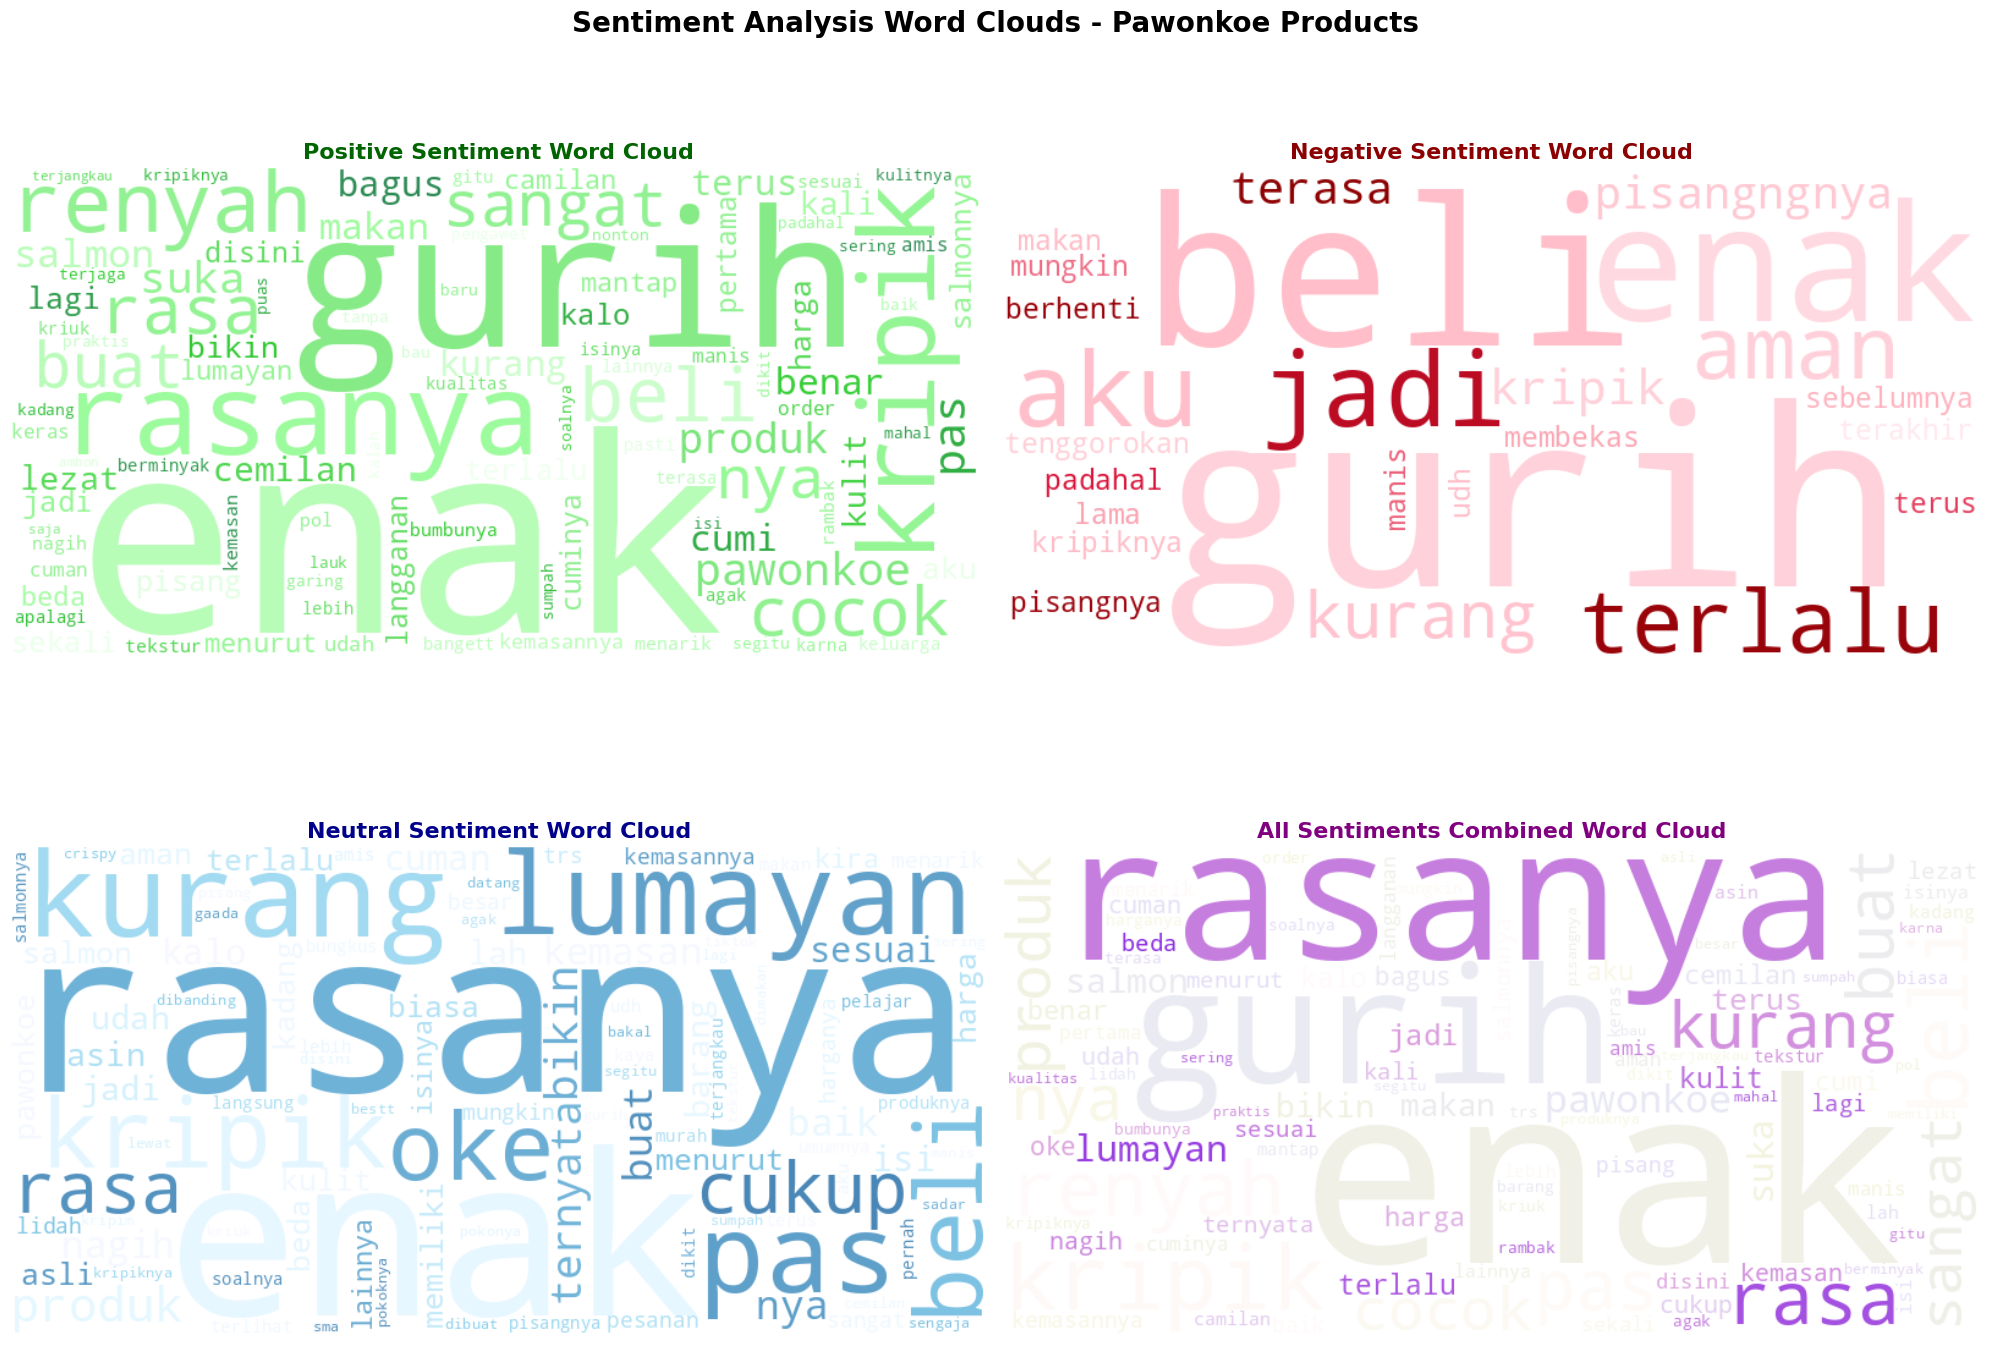


TOP WORDS ANALYSIS
Positive - Total unique words: 536
  Top 5: ['enak(160)', 'gurih(63)', 'rasanya(59)', 'kripik(50)', 'renyah(47)']
Negative - Total unique words: 28
  Top 5: ['gurih(3)', 'beli(2)', 'enak(2)', 'jadi(2)', 'aku(2)']
Neutral - Total unique words: 355
  Top 5: ['rasanya(30)', 'enak(29)', 'kurang(18)', 'lumayan(17)', 'pas(16)']


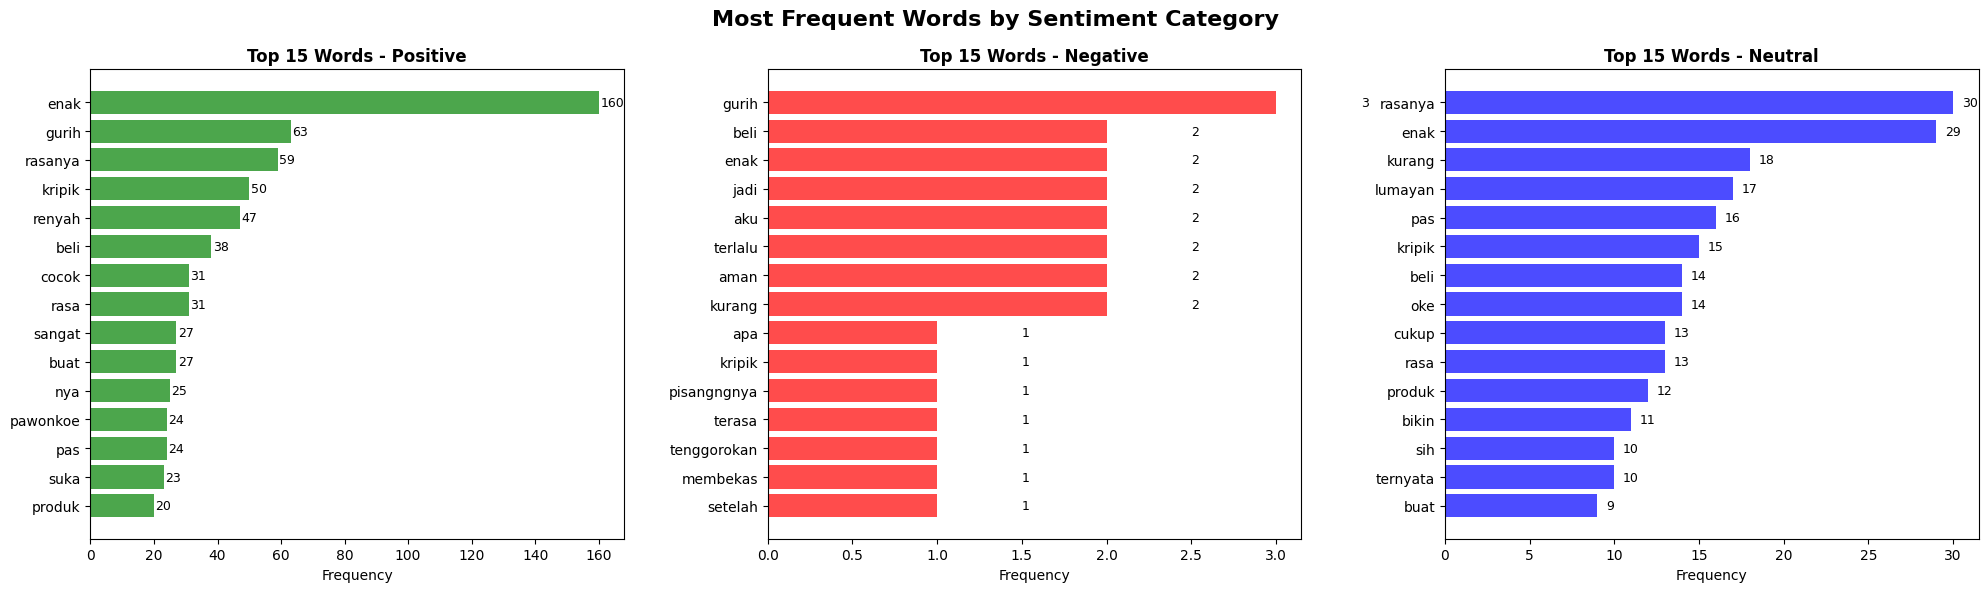

Top words analysis saved as 'top_words_by_sentiment.png'

COMPREHENSIVE TEXT ANALYSIS


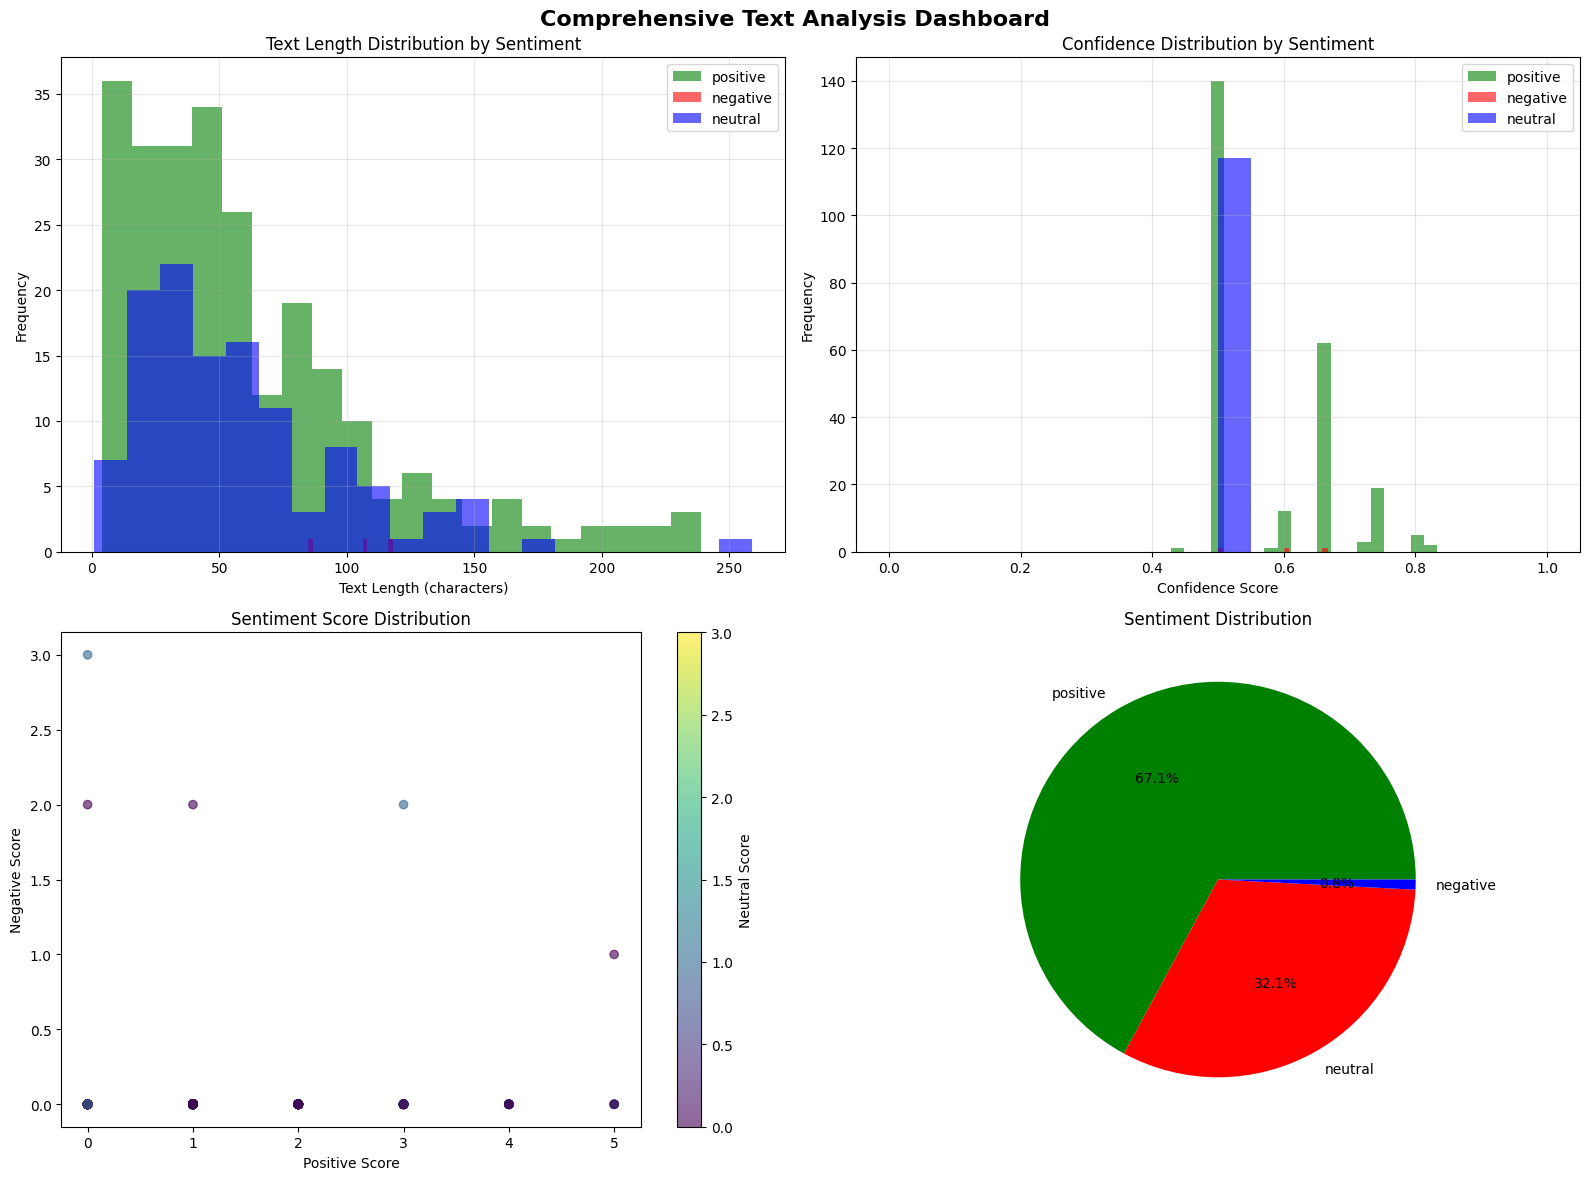

Comprehensive analysis saved as 'comprehensive_text_analysis.png'

✅ WORD CLOUD ANALYSIS COMPLETED!
Generated visualizations:
  - sentiment_wordclouds.png
  - top_words_by_sentiment.png
  - comprehensive_text_analysis.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns
from collections import Counter
import re
from matplotlib.colors import LinearSegmentedColormap

def create_sentiment_wordclouds(results_df, save_plots=True):
    """
    Create word clouds for each sentiment category
    """
    print("CREATING SENTIMENT WORD CLOUDS")
    print("=" * 50)

    # Indonesian stopwords + common words to exclude
    indonesian_stopwords = {
        'yang', 'dan', 'di', 'ke', 'dari', 'untuk', 'dengan', 'pada', 'dalam', 'oleh',
        'karena', 'sebagai', 'juga', 'akan', 'telah', 'sudah', 'masih', 'dapat', 'bisa',
        'ini', 'itu', 'adalah', 'ada', 'atau', 'tidak', 'ya', 'saya', 'kamu', 'dia',
        'kita', 'kami', 'mereka', 'satu', 'dua', 'tiga', 'banyak', 'sedikit', 'semua',
        'setiap', 'sama', 'lain', 'sendiri', 'jika', 'kalau', 'maka', 'tetapi', 'tapi',
        'namun', 'walaupun', 'meskipun', 'setelah', 'sebelum', 'ketika', 'saat', 'waktu',
        'tempat', 'dimana', 'kemana', 'darimana', 'bagaimana', 'mengapa', 'kenapa',
        'berapa', 'kapan', 'siapa', 'apa', 'mana', 'gimana', 'gak', 'ga', 'enggak',
        'nggak', 'bgt', 'banget', 'aja', 'sih', 'kok', 'lho', 'deh', 'dong', 'kan'
    }

    def clean_text_for_wordcloud(text):
        """Clean and prepare text for word cloud"""
        if pd.isna(text) or str(text).strip() == '':
            return ""

        # Convert to lowercase
        text = str(text).lower()

        # Remove special characters but keep Indonesian letters
        text = re.sub(r'[^\w\s]', ' ', text)

        # Split into words
        words = text.split()

        # Filter out stopwords and short words
        filtered_words = [word for word in words
                         if word not in indonesian_stopwords
                         and len(word) > 2
                         and not word.isdigit()]

        return ' '.join(filtered_words)

    # Separate texts by sentiment
    sentiment_texts = {
        'positive': [],
        'negative': [],
        'neutral': []
    }

    for idx, row in results_df.iterrows():
        sentiment = row['predicted_label']
        clean_text = clean_text_for_wordcloud(row['text'])
        if clean_text.strip():
            sentiment_texts[sentiment].append(clean_text)

    print(f"Text distribution:")
    for sentiment, texts in sentiment_texts.items():
        print(f"   {sentiment}: {len(texts)} texts")

    # Create figure with subplots
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))

    # Color schemes for different sentiments
    color_schemes = {
        'positive': ['#2E8B57', '#32CD32', '#90EE90', '#98FB98', '#F0FFF0'],
        'negative': ['#8B0000', '#DC143C', '#FFB6C1', '#FFC0CB', '#FFF0F5'],
        'neutral': ['#4682B4', '#87CEEB', '#E0F6FF', '#F0F8FF', '#F8F8FF'],
        'all': ['#8A2BE2', '#DDA0DD', '#E6E6FA', '#F5F5DC', '#FFFAFA']
    }

    wordcloud_configs = {
        'width': 800,
        'height': 400,
        'max_words': 100,
        'background_color': 'white',
        'collocations': False,
        'relative_scaling': 0.5,
        'min_font_size': 10
    }

    # 1. Positive sentiment word cloud
    ax = axes[0, 0]
    if sentiment_texts['positive']:
        positive_text = ' '.join(sentiment_texts['positive'])
        positive_colormap = LinearSegmentedColormap.from_list("positive", color_schemes['positive'])

        wordcloud = WordCloud(
            colormap=positive_colormap,
            **wordcloud_configs
        ).generate(positive_text)

        ax.imshow(wordcloud, interpolation='bilinear')
        ax.set_title('Positive Sentiment Word Cloud', fontsize=16, fontweight='bold', color='darkgreen')
    else:
        ax.text(0.5, 0.5, 'No Positive Texts', ha='center', va='center',
                transform=ax.transAxes, fontsize=14)
        ax.set_title('Positive Sentiment Word Cloud', fontsize=16, fontweight='bold')

    ax.axis('off')

    # 2. Negative sentiment word cloud
    ax = axes[0, 1]
    if sentiment_texts['negative']:
        negative_text = ' '.join(sentiment_texts['negative'])
        negative_colormap = LinearSegmentedColormap.from_list("negative", color_schemes['negative'])

        wordcloud = WordCloud(
            colormap=negative_colormap,
            **wordcloud_configs
        ).generate(negative_text)

        ax.imshow(wordcloud, interpolation='bilinear')
        ax.set_title('Negative Sentiment Word Cloud', fontsize=16, fontweight='bold', color='darkred')
    else:
        ax.text(0.5, 0.5, 'No Negative Texts', ha='center', va='center',
                transform=ax.transAxes, fontsize=14)
        ax.set_title('Negative Sentiment Word Cloud', fontsize=16, fontweight='bold')

    ax.axis('off')

    # 3. Neutral sentiment word cloud
    ax = axes[1, 0]
    if sentiment_texts['neutral']:
        neutral_text = ' '.join(sentiment_texts['neutral'])
        neutral_colormap = LinearSegmentedColormap.from_list("neutral", color_schemes['neutral'])

        wordcloud = WordCloud(
            colormap=neutral_colormap,
            **wordcloud_configs
        ).generate(neutral_text)

        ax.imshow(wordcloud, interpolation='bilinear')
        ax.set_title('Neutral Sentiment Word Cloud', fontsize=16, fontweight='bold', color='darkblue')
    else:
        ax.text(0.5, 0.5, 'No Neutral Texts', ha='center', va='center',
                transform=ax.transAxes, fontsize=14)
        ax.set_title('Neutral Sentiment Word Cloud', fontsize=16, fontweight='bold')

    ax.axis('off')

    # 4. Combined all sentiments word cloud
    ax = axes[1, 1]
    all_texts = []
    for texts in sentiment_texts.values():
        all_texts.extend(texts)

    if all_texts:
        combined_text = ' '.join(all_texts)
        combined_colormap = LinearSegmentedColormap.from_list("combined", color_schemes['all'])

        wordcloud = WordCloud(
            colormap=combined_colormap,
            **wordcloud_configs
        ).generate(combined_text)

        ax.imshow(wordcloud, interpolation='bilinear')
        ax.set_title('All Sentiments Combined Word Cloud', fontsize=16, fontweight='bold', color='purple')
    else:
        ax.text(0.5, 0.5, 'No Texts Available', ha='center', va='center',
                transform=ax.transAxes, fontsize=14)
        ax.set_title('All Sentiments Combined Word Cloud', fontsize=16, fontweight='bold')

    ax.axis('off')

    plt.suptitle('Sentiment Analysis Word Clouds - Pawonkoe Products',
                 fontsize=20, fontweight='bold', y=0.95)
    plt.tight_layout()

    if save_plots:
        plt.savefig('sentiment_wordclouds.png', dpi=300, bbox_inches='tight')
        print("Word clouds saved as 'sentiment_wordclouds.png'")

    plt.show()

    return sentiment_texts

def create_top_words_analysis(results_df, top_n=15):
    """
    Create bar charts showing top words for each sentiment
    """
    print(f"\nTOP WORDS ANALYSIS")
    print("=" * 30)

    # Indonesian stopwords
    indonesian_stopwords = {
        'yang', 'dan', 'di', 'ke', 'dari', 'untuk', 'dengan', 'pada', 'dalam', 'oleh',
        'karena', 'sebagai', 'juga', 'akan', 'telah', 'sudah', 'masih', 'dapat', 'bisa',
        'ini', 'itu', 'adalah', 'ada', 'atau', 'tidak', 'ya', 'saya', 'kamu', 'dia',
        'kita', 'kami', 'mereka', 'gak', 'ga', 'enggak', 'nggak', 'bgt', 'banget'
    }

    def extract_words(text):
        """Extract and clean words from text"""
        if pd.isna(text):
            return []

        text = str(text).lower()
        words = re.findall(r'\b\w+\b', text)

        # Filter meaningful words
        filtered_words = [word for word in words
                         if word not in indonesian_stopwords
                         and len(word) > 2
                         and not word.isdigit()]

        return filtered_words

    # Collect words by sentiment
    sentiment_words = {
        'positive': [],
        'negative': [],
        'neutral': []
    }

    for _, row in results_df.iterrows():
        sentiment = row['predicted_label']
        words = extract_words(row['text'])
        sentiment_words[sentiment].extend(words)

    # Create visualization
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    colors = ['green', 'red', 'blue']

    for idx, (sentiment, words) in enumerate(sentiment_words.items()):
        ax = axes[idx]

        if words:
            # Count word frequencies
            word_counts = Counter(words)
            top_words = word_counts.most_common(top_n)

            if top_words:
                words_list, counts_list = zip(*top_words)

                bars = ax.barh(range(len(words_list)), counts_list, color=colors[idx], alpha=0.7)
                ax.set_yticks(range(len(words_list)))
                ax.set_yticklabels(words_list)
                ax.invert_yaxis()

                # Add count labels
                for i, (bar, count) in enumerate(zip(bars, counts_list)):
                    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                           str(count), va='center', fontsize=9)

                ax.set_xlabel('Frequency')
                ax.set_title(f'Top {top_n} Words - {sentiment.capitalize()}', fontweight='bold')

                print(f"{sentiment.capitalize()} - Total unique words: {len(set(words))}")
                print(f"  Top 5: {[f'{word}({count})' for word, count in top_words[:5]]}")
        else:
            ax.text(0.5, 0.5, f'No {sentiment} words', ha='center', va='center',
                   transform=ax.transAxes, fontsize=12)
            ax.set_title(f'Top {top_n} Words - {sentiment.capitalize()}', fontweight='bold')

    plt.suptitle('Most Frequent Words by Sentiment Category', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('top_words_by_sentiment.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("Top words analysis saved as 'top_words_by_sentiment.png'")

    return sentiment_words

def create_comprehensive_text_analysis(results_df):
    """
    Create comprehensive text analysis including length distribution and confidence
    """
    print(f"\nCOMPREHENSIVE TEXT ANALYSIS")
    print("=" * 40)

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # 1. Text length distribution by sentiment
    ax = axes[0, 0]
    sentiments = ['positive', 'negative', 'neutral']
    colors = ['green', 'red', 'blue']

    for sentiment, color in zip(sentiments, colors):
        sentiment_data = results_df[results_df['predicted_label'] == sentiment]
        if len(sentiment_data) > 0:
            text_lengths = [len(str(text)) for text in sentiment_data['text']]
            ax.hist(text_lengths, bins=20, alpha=0.6, label=sentiment, color=color)

    ax.set_xlabel('Text Length (characters)')
    ax.set_ylabel('Frequency')
    ax.set_title('Text Length Distribution by Sentiment')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 2. Confidence distribution by sentiment
    ax = axes[0, 1]
    for sentiment, color in zip(sentiments, colors):
        sentiment_data = results_df[results_df['predicted_label'] == sentiment]
        if len(sentiment_data) > 0:
            ax.hist(sentiment_data['confidence'], bins=20, alpha=0.6,
                   label=sentiment, color=color)

    ax.set_xlabel('Confidence Score')
    ax.set_ylabel('Frequency')
    ax.set_title('Confidence Distribution by Sentiment')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 3. Sentiment score distribution
    ax = axes[1, 0]
    pos_scores = results_df['pos_score']
    neg_scores = results_df['neg_score']
    neu_scores = results_df['neu_score']

    ax.scatter(pos_scores, neg_scores, c=neu_scores, cmap='viridis', alpha=0.6)
    ax.set_xlabel('Positive Score')
    ax.set_ylabel('Negative Score')
    ax.set_title('Sentiment Score Distribution')

    # Add color bar
    cbar = plt.colorbar(ax.collections[0], ax=ax)
    cbar.set_label('Neutral Score')

    # 4. Sentiment proportions
    ax = axes[1, 1]
    sentiment_counts = results_df['predicted_label'].value_counts()

    if len(sentiment_counts) > 0:
        wedges, texts, autotexts = ax.pie(sentiment_counts.values,
                                         labels=sentiment_counts.index,
                                         autopct='%1.1f%%',
                                         colors=colors[:len(sentiment_counts)])
        ax.set_title('Sentiment Distribution')

    plt.suptitle('Comprehensive Text Analysis Dashboard', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('comprehensive_text_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("Comprehensive analysis saved as 'comprehensive_text_analysis.png'")

def run_wordcloud_analysis():
    """
    Main function to run word cloud analysis on sentiment results
    """
    print("SENTIMENT WORD CLOUD ANALYSIS PIPELINE")
    print("=" * 60)

    try:
        # Load results from smart relabeling
        if os.path.exists('relabeling_analysis.csv'):
            results_df = pd.read_csv('relabeling_analysis.csv')
            print(f"Loaded sentiment analysis results: {results_df.shape}")
        else:
            print("Error: relabeling_analysis.csv not found")
            print("Please run smart_relabeling first!")
            return None

        # Check if we have the required columns
        required_cols = ['text', 'predicted_label', 'confidence', 'pos_score', 'neg_score', 'neu_score']
        missing_cols = [col for col in required_cols if col not in results_df.columns]

        if missing_cols:
            print(f"Error: Missing columns: {missing_cols}")
            return None

        print(f"\nSentiment distribution:")
        sentiment_counts = results_df['predicted_label'].value_counts()
        for sentiment, count in sentiment_counts.items():
            percentage = count / len(results_df) * 100
            print(f"  {sentiment}: {count} ({percentage:.1f}%)")

        # 1. Create sentiment word clouds
        sentiment_texts = create_sentiment_wordclouds(results_df, save_plots=True)

        # 2. Create top words analysis
        sentiment_words = create_top_words_analysis(results_df, top_n=15)

        # 3. Create comprehensive text analysis
        create_comprehensive_text_analysis(results_df)

        print(f"\n✅ WORD CLOUD ANALYSIS COMPLETED!")
        print(f"Generated visualizations:")
        print(f"  - sentiment_wordclouds.png")
        print(f"  - top_words_by_sentiment.png")
        print(f"  - comprehensive_text_analysis.png")

        return {
            'sentiment_texts': sentiment_texts,
            'sentiment_words': sentiment_words,
            'results_df': results_df
        }

    except Exception as e:
        print(f"Error in word cloud analysis: {e}")
        return None

# Import required libraries check
try:
    from wordcloud import WordCloud
    import os
    print("All required libraries available")
except ImportError as e:
    print(f"Missing library: {e}")
    print("Install with: pip install wordcloud")

# Run word cloud analysis
if __name__ == "__main__":
    wordcloud_results = run_wordcloud_analysis()

### Perbaikan WordCloud

✅ All required libraries available
SENTIMENT WORD CLOUD ANALYSIS PIPELINE (IMPROVED VERSION)
Affix removal: ENABLED
✅ Loaded sentiment analysis results: (365, 9)

Sentiment distribution:
  positive: 245 (67.1%)
  neutral: 117 (32.1%)
  negative: 3 (0.8%)

CREATING SENTIMENT WORD CLOUDS (IMPROVED VERSION)
Using 184 stopwords for filtering

Text distribution:
   positive: 245 texts
   negative: 3 texts
   neutral: 115 texts

✅ Word clouds saved as 'sentiment_wordclouds_improved.png'


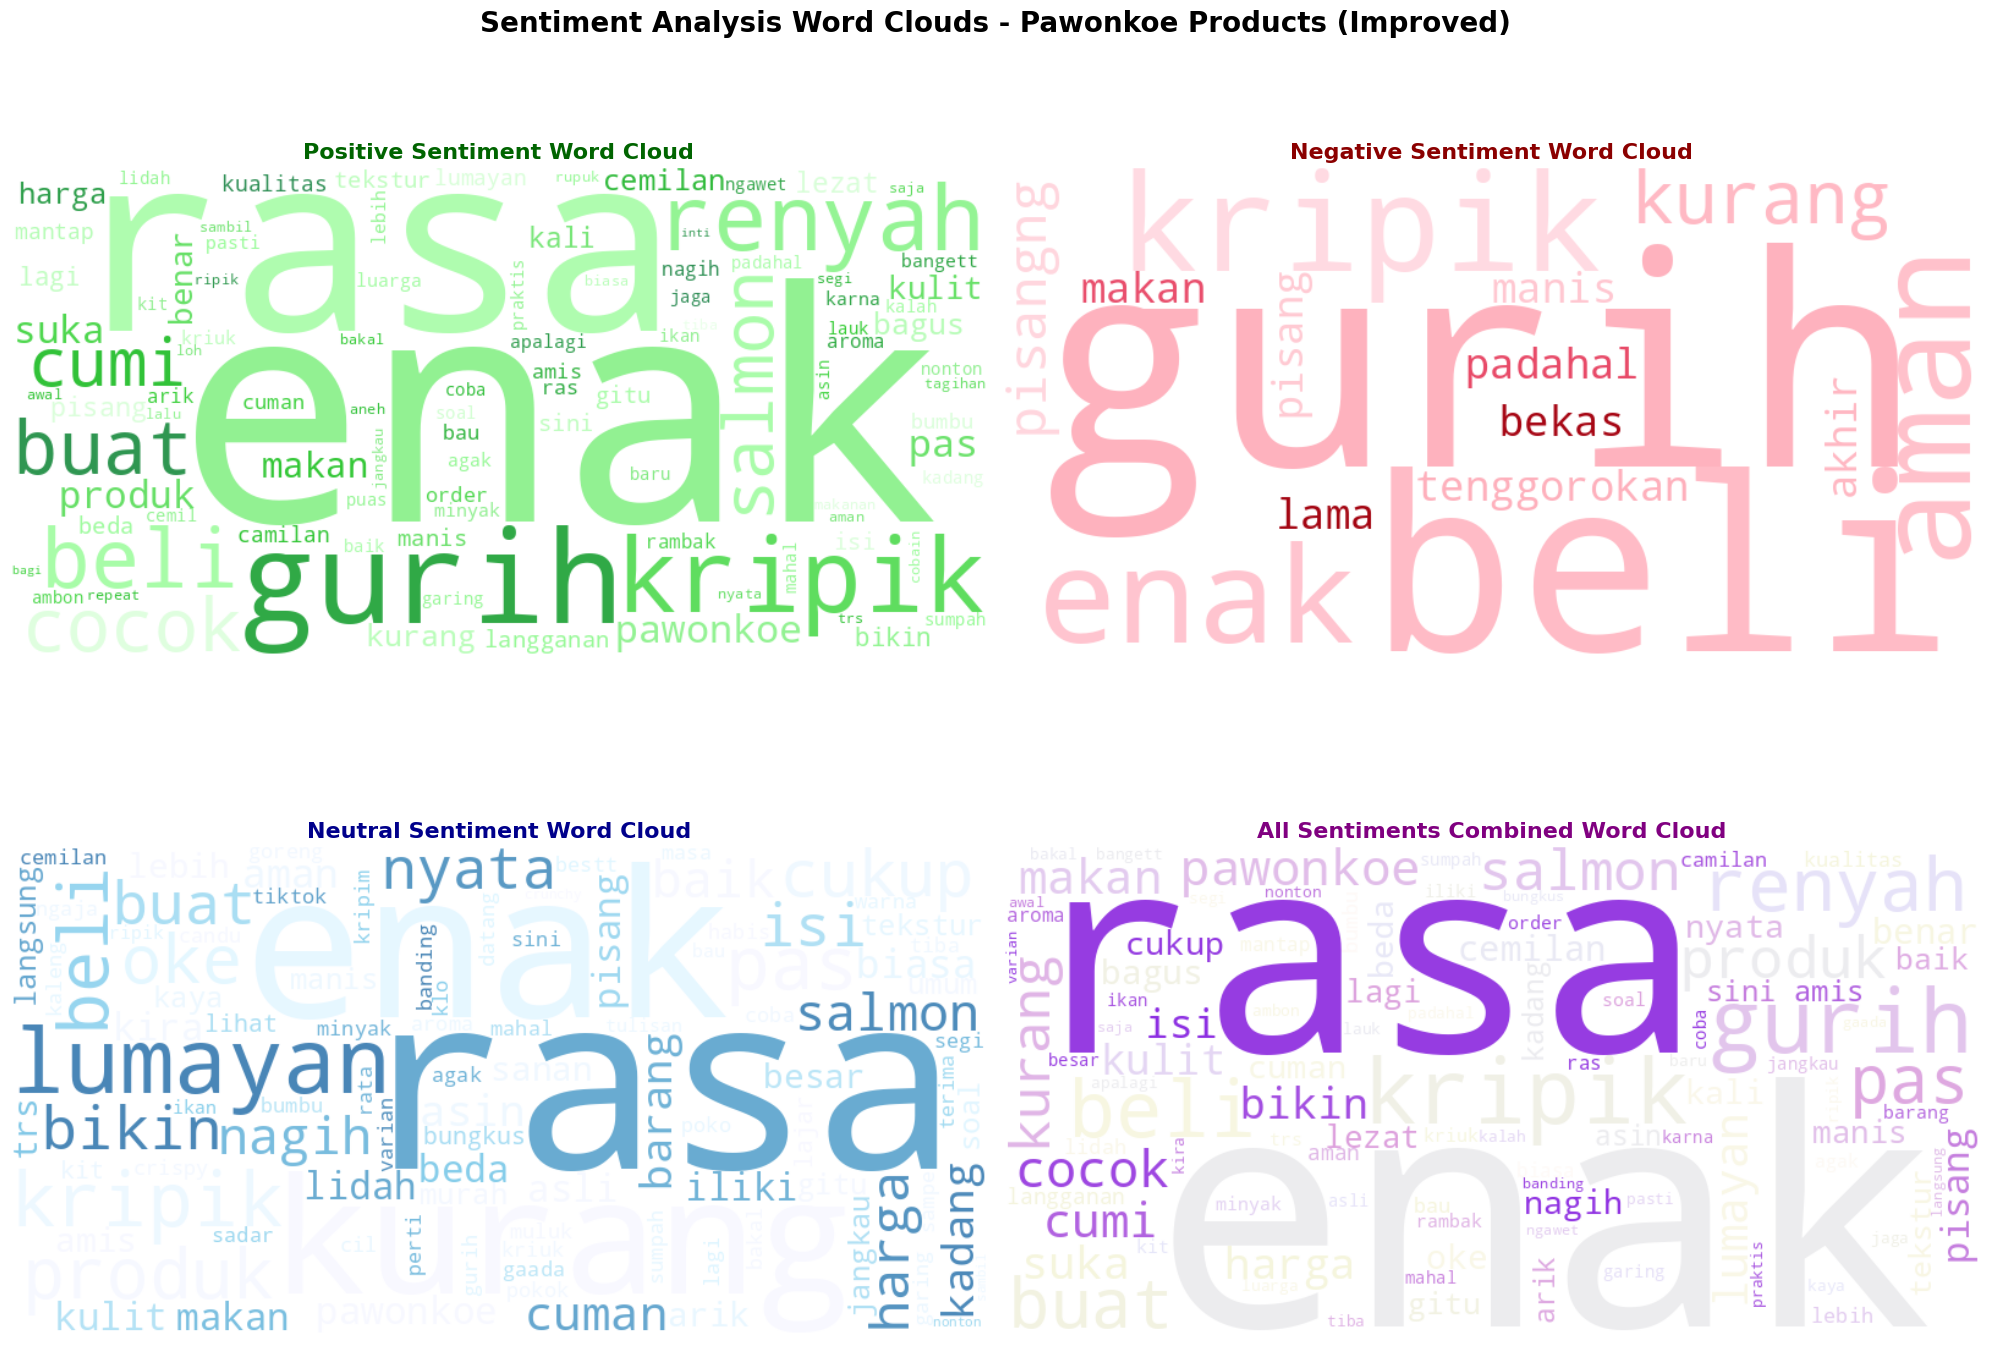



TOP WORDS ANALYSIS (IMPROVED)

Positive - Total unique words: 412
  Top 5: ['enak(162)', 'rasa(93)', 'gurih(66)', 'kripik(54)', 'renyah(48)']

Negative - Total unique words: 15
  Top 5: ['gurih(3)', 'beli(2)', 'kripik(2)', 'enak(2)', 'aman(2)']

Neutral - Total unique words: 266
  Top 5: ['rasa(45)', 'enak(29)', 'kurang(18)', 'lumayan(17)', 'kripik(17)']


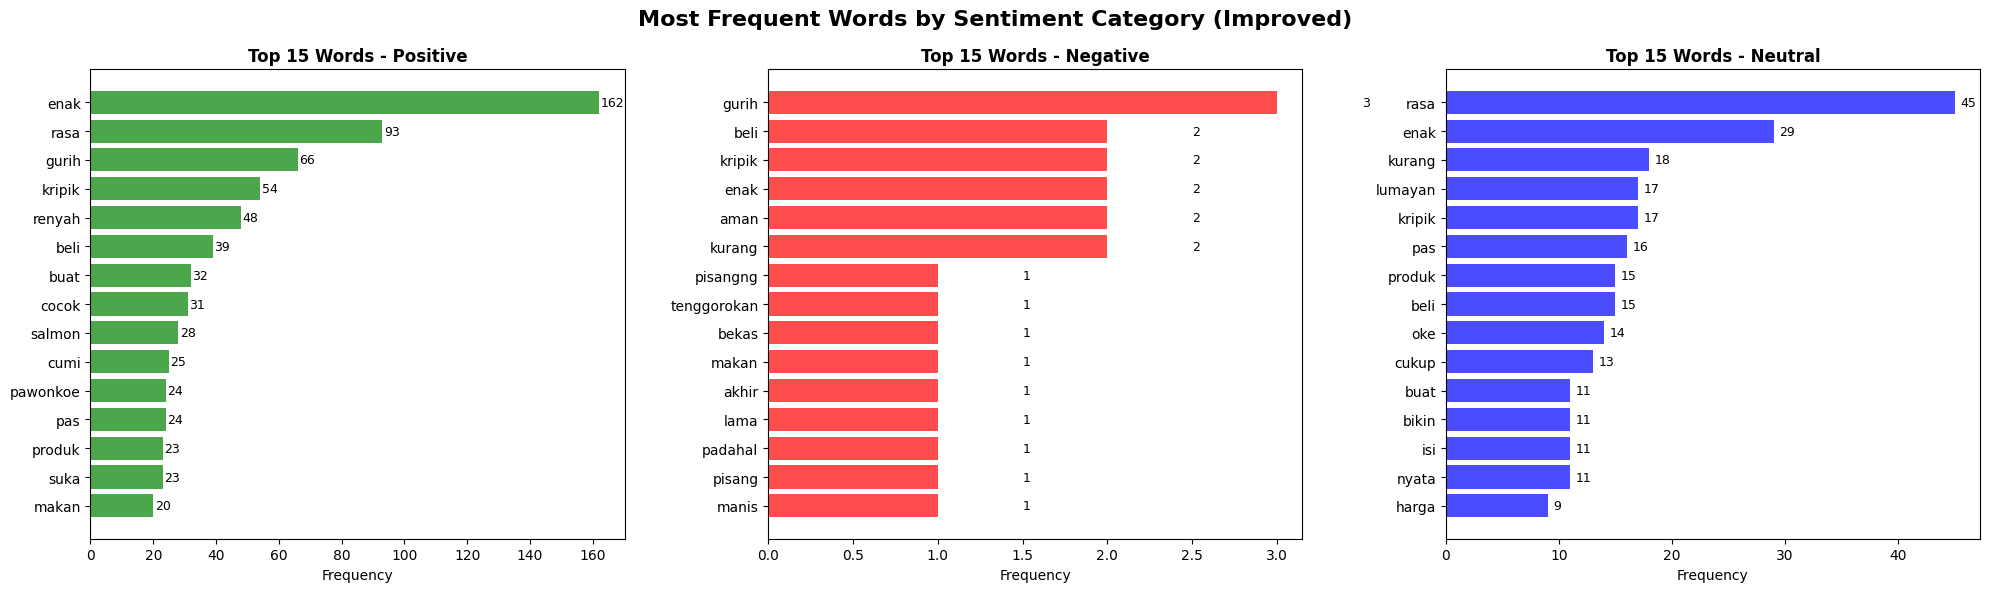


✅ Top words analysis saved as 'top_words_by_sentiment_improved.png'


COMPREHENSIVE TEXT ANALYSIS


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns
from collections import Counter
import re
from matplotlib.colors import LinearSegmentedColormap

def get_comprehensive_indonesian_stopwords():
    """
    Comprehensive list of Indonesian stopwords including affixes and conjunctions
    """
    # Basic stopwords
    basic_stopwords = {
        'yang', 'dan', 'di', 'ke', 'dari', 'untuk', 'dengan', 'pada', 'dalam', 'oleh',
        'karena', 'sebagai', 'juga', 'akan', 'telah', 'sudah', 'masih', 'dapat', 'bisa',
        'ini', 'itu', 'adalah', 'ada', 'atau', 'tidak', 'ya', 'saya', 'kamu', 'dia',
        'kita', 'kami', 'mereka', 'satu', 'dua', 'tiga', 'banyak', 'sedikit', 'semua',
        'setiap', 'sama', 'lain', 'sendiri','ng','kan'
    }

    # Conjunctions (kata hubung)
    conjunctions = {
        'jika', 'kalau', 'maka', 'tetapi', 'tapi', 'namun', 'walaupun', 'meskipun',
        'setelah', 'sebelum', 'ketika', 'saat', 'waktu', 'bila', 'apabila', 'andai',
        'agar', 'supaya', 'hingga', 'sampai', 'sejak', 'semenjak', 'sedangkan', 'sementara'
    }

    # Question words
    question_words = {
        'tempat', 'dimana', 'kemana', 'darimana', 'bagaimana', 'mengapa', 'kenapa',
        'berapa', 'kapan', 'siapa', 'apa', 'mana', 'gimana'
    }

    # Informal words and particles
    informal_particles = {
        'gak', 'ga', 'enggak', 'nggak', 'bgt', 'banget', 'aja', 'sih', 'kok',
        'lho', 'deh', 'dong', 'kan', 'nih', 'tuh', 'dah', 'tau', 'kalo', 'emang',
        'jadi', 'terus', 'trus', 'iya', 'yah', 'yg', 'udah', 'udh', 'blm', 'belum','nya','henti','suai','rja', 'lah', 'nah', 'ring', 'sma', 'adaan', 'urutku', 'tama', 'hat', 'masan', 'pol', 'nasaran', 'packaging'
    }

    # Pronouns
    pronouns = {
        'aku', 'kau', 'engkau', 'ia', 'beliau', 'nya', 'mu', 'ku', 'anda',
        'mereka', 'kalian', 'kita', 'kami'
    }

    # Common affixed words that should be removed
    common_affixed = {
        'tersebut', 'demikian', 'sebagainya', 'lainnya', 'sendiri', 'sekarang',
        'kemudian', 'selain', 'selama', 'sebelumnya', 'sesudah', 'beberapa',
        'berikut', 'masing', 'melalui', 'melainkan', 'menjadi', 'mengenai',
        'menurut', 'misalnya', 'sekitar', 'seolah', 'seringkali', 'terhadap',
        'termasuk', 'terlalu', 'tersedia', 'mungkin', 'sekali', 'sangat','bel','asa'
    }

    # Prepositions
    prepositions = {
        'di', 'ke', 'dari', 'pada', 'dalam', 'kepada', 'terhadap', 'oleh',
        'tentang', 'antara', 'hingga', 'sampai', 'lewat', 'tanpa'
    }

    # Time-related words
    time_words = {
        'hari', 'tahun', 'bulan', 'minggu', 'jam', 'menit', 'detik',
        'pagi', 'siang', 'sore', 'malam', 'besok', 'kemarin', 'nanti'
    }

    # Combine all stopwords
    all_stopwords = (
        basic_stopwords | conjunctions | question_words | informal_particles |
        pronouns | common_affixed | prepositions | time_words
    )

    return all_stopwords

def remove_affixes(word):
    """
    Remove common Indonesian affixes (imbuhan) to get the root word
    This helps in reducing duplicate words with different affixes
    """
    # Prefix removal (awalan)
    prefixes = ['me', 'mem', 'men', 'meng', 'meny', 'di', 'ter', 'ber', 'per', 'pe', 'ke', 'se']
    # Suffix removal (akhiran)
    suffixes = ['nya']

    original_word = word

    # Remove suffix first
    for suffix in sorted(suffixes, key=len, reverse=True):
        if word.endswith(suffix) and len(word) > len(suffix) + 2:
            word = word[:-len(suffix)]
            break

    # Remove prefix
    for prefix in sorted(prefixes, key=len, reverse=True):
        if word.startswith(prefix) and len(word) > len(prefix) + 2:
            word = word[len(prefix):]
            break

    # Return cleaned word if it's still meaningful, otherwise return original
    return word if len(word) > 2 else original_word

def create_sentiment_wordclouds(results_df, save_plots=True, remove_affixes_flag=True):
    """
    Create word clouds for each sentiment category with improved filtering

    Parameters:
    - results_df: DataFrame with sentiment analysis results
    - save_plots: Whether to save the plots
    - remove_affixes_flag: Whether to remove affixes from words
    """
    print("CREATING SENTIMENT WORD CLOUDS (IMPROVED VERSION)")
    print("=" * 50)

    # Get comprehensive stopwords
    indonesian_stopwords = get_comprehensive_indonesian_stopwords()

    print(f"Using {len(indonesian_stopwords)} stopwords for filtering")

    def clean_text_for_wordcloud(text):
        """Clean and prepare text for word cloud with improved filtering"""
        if pd.isna(text) or str(text).strip() == '':
            return ""

        # Convert to lowercase
        text = str(text).lower()

        # Remove URLs
        text = re.sub(r'http\S+|www\S+', '', text)

        # Remove mentions and hashtags
        text = re.sub(r'@\w+|#\w+', '', text)

        # Remove numbers
        text = re.sub(r'\d+', '', text)

        # Remove special characters but keep Indonesian letters
        text = re.sub(r'[^\w\s]', ' ', text)

        # Split into words
        words = text.split()

        # Filter and process words
        filtered_words = []
        for word in words:
            # Skip if in stopwords
            if word in indonesian_stopwords:
                continue

            # Skip short words
            if len(word) <= 2:
                continue

            # Skip if all digits
            if word.isdigit():
                continue

            # Remove affixes if flag is set
            if remove_affixes_flag:
                word = remove_affixes(word)

            # Add if still valid
            if len(word) > 2 and word not in indonesian_stopwords:
                filtered_words.append(word)

        return ' '.join(filtered_words)

    # Separate texts by sentiment
    sentiment_texts = {
        'positive': [],
        'negative': [],
        'neutral': []
    }

    for idx, row in results_df.iterrows():
        sentiment = row['predicted_label']
        clean_text = clean_text_for_wordcloud(row['text'])
        if clean_text.strip():
            sentiment_texts[sentiment].append(clean_text)

    print(f"\nText distribution:")
    for sentiment, texts in sentiment_texts.items():
        print(f"   {sentiment}: {len(texts)} texts")

    # Create figure with subplots
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))

    # Color schemes for different sentiments
    color_schemes = {
        'positive': ['#2E8B57', '#32CD32', '#90EE90', '#98FB98', '#F0FFF0'],
        'negative': ['#8B0000', '#DC143C', '#FFB6C1', '#FFC0CB', '#FFF0F5'],
        'neutral': ['#4682B4', '#87CEEB', '#E0F6FF', '#F0F8FF', '#F8F8FF'],
        'all': ['#8A2BE2', '#DDA0DD', '#E6E6FA', '#F5F5DC', '#FFFAFA']
    }

    wordcloud_configs = {
        'width': 800,
        'height': 400,
        'max_words': 100,
        'background_color': 'white',
        'collocations': False,
        'relative_scaling': 0.5,
        'min_font_size': 10
    }

    # 1. Positive sentiment word cloud
    ax = axes[0, 0]
    if sentiment_texts['positive']:
        positive_text = ' '.join(sentiment_texts['positive'])
        positive_colormap = LinearSegmentedColormap.from_list("positive", color_schemes['positive'])

        wordcloud = WordCloud(
            colormap=positive_colormap,
            **wordcloud_configs
        ).generate(positive_text)

        ax.imshow(wordcloud, interpolation='bilinear')
        ax.set_title('Positive Sentiment Word Cloud', fontsize=16, fontweight='bold', color='darkgreen')
    else:
        ax.text(0.5, 0.5, 'No Positive Texts', ha='center', va='center',
                transform=ax.transAxes, fontsize=14)
        ax.set_title('Positive Sentiment Word Cloud', fontsize=16, fontweight='bold')

    ax.axis('off')

    # 2. Negative sentiment word cloud
    ax = axes[0, 1]
    if sentiment_texts['negative']:
        negative_text = ' '.join(sentiment_texts['negative'])
        negative_colormap = LinearSegmentedColormap.from_list("negative", color_schemes['negative'])

        wordcloud = WordCloud(
            colormap=negative_colormap,
            **wordcloud_configs
        ).generate(negative_text)

        ax.imshow(wordcloud, interpolation='bilinear')
        ax.set_title('Negative Sentiment Word Cloud', fontsize=16, fontweight='bold', color='darkred')
    else:
        ax.text(0.5, 0.5, 'No Negative Texts', ha='center', va='center',
                transform=ax.transAxes, fontsize=14)
        ax.set_title('Negative Sentiment Word Cloud', fontsize=16, fontweight='bold')

    ax.axis('off')

    # 3. Neutral sentiment word cloud
    ax = axes[1, 0]
    if sentiment_texts['neutral']:
        neutral_text = ' '.join(sentiment_texts['neutral'])
        neutral_colormap = LinearSegmentedColormap.from_list("neutral", color_schemes['neutral'])

        wordcloud = WordCloud(
            colormap=neutral_colormap,
            **wordcloud_configs
        ).generate(neutral_text)

        ax.imshow(wordcloud, interpolation='bilinear')
        ax.set_title('Neutral Sentiment Word Cloud', fontsize=16, fontweight='bold', color='darkblue')
    else:
        ax.text(0.5, 0.5, 'No Neutral Texts', ha='center', va='center',
                transform=ax.transAxes, fontsize=14)
        ax.set_title('Neutral Sentiment Word Cloud', fontsize=16, fontweight='bold')

    ax.axis('off')

    # 4. Combined all sentiments word cloud
    ax = axes[1, 1]
    all_texts = []
    for texts in sentiment_texts.values():
        all_texts.extend(texts)

    if all_texts:
        combined_text = ' '.join(all_texts)
        combined_colormap = LinearSegmentedColormap.from_list("combined", color_schemes['all'])

        wordcloud = WordCloud(
            colormap=combined_colormap,
            **wordcloud_configs
        ).generate(combined_text)

        ax.imshow(wordcloud, interpolation='bilinear')
        ax.set_title('All Sentiments Combined Word Cloud', fontsize=16, fontweight='bold', color='purple')
    else:
        ax.text(0.5, 0.5, 'No Texts Available', ha='center', va='center',
                transform=ax.transAxes, fontsize=14)
        ax.set_title('All Sentiments Combined Word Cloud', fontsize=16, fontweight='bold')

    ax.axis('off')

    plt.suptitle('Sentiment Analysis Word Clouds - Pawonkoe Products (Improved)',
                 fontsize=20, fontweight='bold', y=0.95)
    plt.tight_layout()

    if save_plots:
        plt.savefig('sentiment_wordclouds_improved.png', dpi=300, bbox_inches='tight')
        print("\n✅ Word clouds saved as 'sentiment_wordclouds_improved.png'")

    plt.show()

    return sentiment_texts

def create_top_words_analysis(results_df, top_n=15, remove_affixes_flag=True):
    """
    Create bar charts showing top words for each sentiment with improved filtering
    """
    print(f"\nTOP WORDS ANALYSIS (IMPROVED)")
    print("=" * 30)

    # Get comprehensive stopwords
    indonesian_stopwords = get_comprehensive_indonesian_stopwords()

    def extract_words(text):
        """Extract and clean words from text with improved filtering"""
        if pd.isna(text):
            return []

        text = str(text).lower()

        # Remove URLs, mentions, hashtags
        text = re.sub(r'http\S+|www\S+|@\w+|#\w+', '', text)

        # Extract words
        words = re.findall(r'\b\w+\b', text)

        # Filter and process words
        filtered_words = []
        for word in words:
            # Skip stopwords
            if word in indonesian_stopwords:
                continue

            # Skip short words and digits
            if len(word) <= 2 or word.isdigit():
                continue

            # Remove affixes if flag is set
            if remove_affixes_flag:
                word = remove_affixes(word)

            # Add if still valid
            if len(word) > 2 and word not in indonesian_stopwords:
                filtered_words.append(word)

        return filtered_words

    # Collect words by sentiment
    sentiment_words = {
        'positive': [],
        'negative': [],
        'neutral': []
    }

    for _, row in results_df.iterrows():
        sentiment = row['predicted_label']
        words = extract_words(row['text'])
        sentiment_words[sentiment].extend(words)

    # Create visualization
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    colors = ['green', 'red', 'blue']

    for idx, (sentiment, words) in enumerate(sentiment_words.items()):
        ax = axes[idx]

        if words:
            # Count word frequencies
            word_counts = Counter(words)
            top_words = word_counts.most_common(top_n)

            if top_words:
                words_list, counts_list = zip(*top_words)

                bars = ax.barh(range(len(words_list)), counts_list, color=colors[idx], alpha=0.7)
                ax.set_yticks(range(len(words_list)))
                ax.set_yticklabels(words_list)
                ax.invert_yaxis()

                # Add count labels
                for i, (bar, count) in enumerate(zip(bars, counts_list)):
                    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                           str(count), va='center', fontsize=9)

                ax.set_xlabel('Frequency')
                ax.set_title(f'Top {top_n} Words - {sentiment.capitalize()}', fontweight='bold')

                print(f"\n{sentiment.capitalize()} - Total unique words: {len(set(words))}")
                print(f"  Top 5: {[f'{word}({count})' for word, count in top_words[:5]]}")
        else:
            ax.text(0.5, 0.5, f'No {sentiment} words', ha='center', va='center',
                   transform=ax.transAxes, fontsize=12)
            ax.set_title(f'Top {top_n} Words - {sentiment.capitalize()}', fontweight='bold')

    plt.suptitle('Most Frequent Words by Sentiment Category (Improved)', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('top_words_by_sentiment_improved.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("\n✅ Top words analysis saved as 'top_words_by_sentiment_improved.png'")

    return sentiment_words

def create_comprehensive_text_analysis(results_df):
    """
    Create comprehensive text analysis including length distribution and confidence
    """
    print(f"\nCOMPREHENSIVE TEXT ANALYSIS")
    print("=" * 40)

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # 1. Text length distribution by sentiment
    ax = axes[0, 0]
    sentiments = ['positive', 'negative', 'neutral']
    colors = ['green', 'red', 'blue']

    for sentiment, color in zip(sentiments, colors):
        sentiment_data = results_df[results_df['predicted_label'] == sentiment]
        if len(sentiment_data) > 0:
            text_lengths = [len(str(text)) for text in sentiment_data['text']]
            ax.hist(text_lengths, bins=20, alpha=0.6, label=sentiment, color=color)

    ax.set_xlabel('Text Length (characters)')
    ax.set_ylabel('Frequency')
    ax.set_title('Text Length Distribution by Sentiment')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 2. Confidence distribution by sentiment
    ax = axes[0, 1]
    for sentiment, color in zip(sentiments, colors):
        sentiment_data = results_df[results_df['predicted_label'] == sentiment]
        if len(sentiment_data) > 0:
            ax.hist(sentiment_data['confidence'], bins=20, alpha=0.6,
                   label=sentiment, color=color)

    ax.set_xlabel('Confidence Score')
    ax.set_ylabel('Frequency')
    ax.set_title('Confidence Distribution by Sentiment')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 3. Sentiment score distribution
    ax = axes[1, 0]
    pos_scores = results_df['pos_score']
    neg_scores = results_df['neg_score']
    neu_scores = results_df['neu_score']

    ax.scatter(pos_scores, neg_scores, c=neu_scores, cmap='viridis', alpha=0.6)
    ax.set_xlabel('Positive Score')
    ax.set_ylabel('Negative Score')
    ax.set_title('Sentiment Score Distribution')

    # Add color bar
    cbar = plt.colorbar(ax.collections[0], ax=ax)
    cbar.set_label('Neutral Score')

    # 4. Sentiment proportions
    ax = axes[1, 1]
    sentiment_counts = results_df['predicted_label'].value_counts()

    if len(sentiment_counts) > 0:
        wedges, texts, autotexts = ax.pie(sentiment_counts.values,
                                         labels=sentiment_counts.index,
                                         autopct='%1.1f%%',
                                         colors=colors[:len(sentiment_counts)])
        ax.set_title('Sentiment Distribution')

    plt.suptitle('Comprehensive Text Analysis Dashboard', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('comprehensive_text_analysis_improved.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("\n✅ Comprehensive analysis saved as 'comprehensive_text_analysis_improved.png'")

def run_wordcloud_analysis(remove_affixes_flag=True):
    """
    Main function to run word cloud analysis on sentiment results

    Parameters:
    - remove_affixes_flag: If True, removes Indonesian affixes (me-, di-, -kan, -an, etc.)
    """
    print("SENTIMENT WORD CLOUD ANALYSIS PIPELINE (IMPROVED VERSION)")
    print("=" * 60)
    print(f"Affix removal: {'ENABLED' if remove_affixes_flag else 'DISABLED'}")
    print("=" * 60)

    try:
        import os

        # Load results from smart relabeling
        if os.path.exists('relabeling_analysis.csv'):
            results_df = pd.read_csv('relabeling_analysis.csv')
            print(f"✅ Loaded sentiment analysis results: {results_df.shape}")
        else:
            print("❌ Error: relabeling_analysis.csv not found")
            print("Please run smart_relabeling first!")
            return None

        # Check if we have the required columns
        required_cols = ['text', 'predicted_label', 'confidence', 'pos_score', 'neg_score', 'neu_score']
        missing_cols = [col for col in required_cols if col not in results_df.columns]

        if missing_cols:
            print(f"❌ Error: Missing columns: {missing_cols}")
            return None

        print(f"\nSentiment distribution:")
        sentiment_counts = results_df['predicted_label'].value_counts()
        for sentiment, count in sentiment_counts.items():
            percentage = count / len(results_df) * 100
            print(f"  {sentiment}: {count} ({percentage:.1f}%)")

        # 1. Create sentiment word clouds
        print("\n" + "=" * 60)
        sentiment_texts = create_sentiment_wordclouds(results_df, save_plots=True,
                                                     remove_affixes_flag=remove_affixes_flag)

        # 2. Create top words analysis
        print("\n" + "=" * 60)
        sentiment_words = create_top_words_analysis(results_df, top_n=15,
                                                   remove_affixes_flag=remove_affixes_flag)

        # 3. Create comprehensive text analysis
        print("\n" + "=" * 60)
        create_comprehensive_text_analysis(results_df)

        print(f"\n" + "=" * 60)
        print(f"✅ WORD CLOUD ANALYSIS COMPLETED!")
        print(f"=" * 60)
        print(f"Generated visualizations:")
        print(f"  ✓ sentiment_wordclouds_improved.png")
        print(f"  ✓ top_words_by_sentiment_improved.png")
        print(f"  ✓ comprehensive_text_analysis_improved.png")

        return {
            'sentiment_texts': sentiment_texts,
            'sentiment_words': sentiment_words,
            'results_df': results_df
        }

    except Exception as e:
        print(f"❌ Error in word cloud analysis: {e}")
        import traceback
        traceback.print_exc()
        return None

# Import required libraries check
try:
    from wordcloud import WordCloud
    import os
    print("✅ All required libraries available")
except ImportError as e:
    print(f"❌ Missing library: {e}")
    print("Install with: pip install wordcloud")

# Run word cloud analysis
if __name__ == "__main__":
    # Run with affix removal enabled (recommended)
    wordcloud_results = run_wordcloud_analysis(remove_affixes_flag=True)

    # If you want to disable affix removal, use:
    # wordcloud_results = run_wordcloud_analysis(remove_affixes_flag=False)

## Tambahan (Tanpa Mengubah Model): Confusion Matrix & Uji Chi-Square (Rating Kepuasan vs Prediksi Sentimen)
Cell di bawah ini **hanya menambahkan analisis**. Pastikan file `Sentimen.xlsx` dan `sentiment_features_for_xgboost.csv` sudah ada di folder kerja notebook.

In [ ]:
# =====================================================
# TAMBAHAN A: Load output prediksi mBERT (tanpa retraining)
# =====================================================

import pandas as pd
import numpy as np

bert_out = pd.read_csv("sentiment_features_for_xgboost.csv")

print("=== INFO OUTPUT mBERT ===")
print("Shape:", bert_out.shape)
print("Kolom:", bert_out.columns.tolist())
display(bert_out.head(3))


In [ ]:
# =====================================================
# TAMBAHAN B: Confusion Matrix + Classification Report (Evaluasi)
# =====================================================

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

assert "true_label" in bert_out.columns, "Kolom 'true_label' tidak ditemukan di sentiment_features_for_xgboost.csv"
assert "predicted_label" in bert_out.columns, "Kolom 'predicted_label' tidak ditemukan di sentiment_features_for_xgboost.csv"

y_true = bert_out["true_label"].astype(str)
y_pred = bert_out["predicted_label"].astype(str)

labels = sorted(list(set(y_true.unique()) | set(y_pred.unique())))

print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, labels=labels))

cm = confusion_matrix(y_true, y_pred, labels=labels)

cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels])
print("\n=== Confusion Matrix (Tabel) ===")
display(cm_df)

plt.figure(figsize=(6,5))
plt.imshow(cm)
plt.xticks(range(len(labels)), labels, rotation=45, ha="right")
plt.yticks(range(len(labels)), labels)
plt.title("Confusion Matrix - mBERT Sentiment")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.tight_layout()
plt.show()


In [ ]:
# =====================================================
# TAMBAHAN C: Load data rating kepuasan + rapihkan kolom
# =====================================================

import pandas as pd
import numpy as np

df_raw = pd.read_excel("Sentimen.xlsx")

def _clean_colname(c: str) -> str:
    c = str(c).strip().replace("\n", " ")
    c = " ".join(c.split())
    return c

df_raw.columns = [_clean_colname(c) for c in df_raw.columns]

def _find_col_by_keywords(columns, keywords):
    for c in columns:
        cl = c.lower()
        if all(k.lower() in cl for k in keywords):
            return c
    return None

col_pendapat = _find_col_by_keywords(df_raw.columns, ["pendapat", "produk"])
col_rating_kepuasan = _find_col_by_keywords(df_raw.columns, ["tingkat kepuasan", "keseluruhan"])

print("Kolom pendapat terdeteksi:", col_pendapat)
print("Kolom rating kepuasan terdeteksi:", col_rating_kepuasan)

df_report = df_raw.copy()
rename_map = {}
if col_pendapat is not None: rename_map[col_pendapat] = "pendapat"
if col_rating_kepuasan is not None: rename_map[col_rating_kepuasan] = "rating_kepuasan"
df_report = df_report.rename(columns=rename_map)

assert "pendapat" in df_report.columns, "Kolom 'pendapat' tidak ditemukan setelah rename. Cek deteksi kolom di atas."
assert "rating_kepuasan" in df_report.columns, "Kolom 'rating_kepuasan' tidak ditemukan setelah rename. Cek deteksi kolom di atas."

df_report["rating_kepuasan"] = pd.to_numeric(df_report["rating_kepuasan"], errors="coerce")

def map_kepuasan(r):
    if r in [1, 2]:
        return "Tidak Puas"
    elif r == 3:
        return "Netral"
    elif r in [4, 5]:
        return "Puas"
    return np.nan

df_report["kategori_kepuasan"] = df_report["rating_kepuasan"].apply(map_kepuasan)

print("\n=== Preview data (rapi untuk laporan) ===")
display(df_report.head(3))
display(df_report.tail(3))


In [ ]:
# =====================================================
# TAMBAHAN D: Sinkronisasi rating ↔ prediksi sentimen + Crosstab
# =====================================================

import re
import pandas as pd

candidates = ["text", "texts", "review", "sentence", "kalimat", "pendapat", "clean_text", "processed_text"]
text_col = next((c for c in candidates if c in bert_out.columns), None)

print("Kolom teks pada output mBERT terdeteksi:", text_col)

def norm_text(s):
    s = "" if pd.isna(s) else str(s)
    s = s.lower().strip()
    s = re.sub(r"\s+", " ", s)
    return s

if text_col is not None:
    df_left = df_report.copy()
    df_right = bert_out.copy()
    df_left["_key_text"] = df_left["pendapat"].apply(norm_text)
    df_right["_key_text"] = df_right[text_col].apply(norm_text)

    df_merge = df_left.merge(
        df_right[["_key_text", "predicted_label", "true_label"]],
        on="_key_text",
        how="inner"
    )
    print(f"Sinkronisasi via TEXT: {len(df_merge)}/{len(df_report)} baris match.")
else:
    if len(df_report) == len(bert_out):
        df_merge = pd.concat(
            [df_report.reset_index(drop=True),
             bert_out[["predicted_label", "true_label"]].reset_index(drop=True)],
            axis=1
        )
        print("Tidak ada kolom teks. Sinkronisasi via INDEX (jumlah baris sama).")
    else:
        raise ValueError("Tidak bisa sinkronisasi: kolom teks tidak ditemukan dan jumlah baris tidak sama.")

ct_count = pd.crosstab(df_merge["kategori_kepuasan"], df_merge["predicted_label"])
ct_pct = (pd.crosstab(df_merge["kategori_kepuasan"], df_merge["predicted_label"], normalize="index") * 100).round(2)

print("\n=== Crosstab Kepuasan vs Prediksi Sentimen (COUNT) ===")
display(ct_count)

print("\n=== Crosstab Kepuasan vs Prediksi Sentimen (PERSEN per baris) ===")
display(ct_pct)


In [ ]:
# =====================================================
# TAMBAHAN E: Uji Chi-Square + Cramer's V
# =====================================================

import numpy as np
import pandas as pd

contingency = pd.crosstab(df_merge["kategori_kepuasan"], df_merge["predicted_label"])
assert contingency.shape[0] > 0 and contingency.shape[1] > 0, "Tabel kontingensi kosong. Cek proses merge."

try:
    from scipy.stats import chi2_contingency
    chi2, p, dof, expected = chi2_contingency(contingency)

    print("=== Uji Chi-Square (Kepuasan vs Prediksi Sentimen) ===")
    print(f"Chi-square: {chi2:.4f}")
    print(f"DoF: {dof}")
    print(f"p-value: {p:.6f}")

    expected_df = pd.DataFrame(expected, index=contingency.index, columns=contingency.columns)
    print("\n=== Expected Frequencies (Tabel Ekspektasi) ===")
    display(expected_df.round(2))

    n = contingency.to_numpy().sum()
    r, k = contingency.shape
    cramers_v = np.sqrt((chi2 / n) / (min(r-1, k-1)))
    print(f"\nCramer's V: {cramers_v:.4f}")

except Exception as e:
    print("Gagal menjalankan chi-square. Error:")
    print(e)
    print("Jika perlu, install scipy atau gunakan alternatif uji Spearman untuk rating numerik.")


In [ ]:
# =====================================================
# mBERT FINAL - FULL CODE (sesuai mbert final.ipynb)
# NOTE: TIDAK UBAH MODEL / KONSEP
# TAMBAHAN HANYA: TABEL TEKS SETELAH EVALUASI (CHECK SESUAI/TIDAK)
# =====================================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import re
import pickle
import warnings
warnings.filterwarnings('ignore')

try:
    from IPython.display import display
except Exception:
    def display(x): print(x)

class ThesisDataPreprocessor:
    """Data preprocessing for SENTIMENT analysis only"""

    def __init__(self, sentiment_file="Sentimen.xlsx"):
        self.sentiment_file = sentiment_file
        self.preprocessing_log = []
        self.transformations = {}

    def log_step(self, step_name, description, before_shape=None, after_shape=None, details=None):
        step_info = {
            'step': step_name,
            'description': description,
            'before_shape': before_shape,
            'after_shape': after_shape,
            'details': details
        }
        self.preprocessing_log.append(step_info)

        print(f"\n✓ {step_name}: {description}")
        if before_shape and after_shape:
            print(f"   Shape: {before_shape} → {after_shape}")
        if details:
            for key, value in details.items():
                print(f"   {key}: {value}")

    def load_sentiment_data(self):
        """Load sentiment dataset"""
        print("LOADING SENTIMENT DATA")
        print("=" * 50)

        try:
            df = pd.read_excel(self.sentiment_file)
            self.log_step(
                "DATA LOADED",
                f"Berhasil memuat dataset sentiment dari {self.sentiment_file}",
                after_shape=df.shape,
                details={'Columns': list(df.columns)}
            )
            return df

        except Exception as e:
            print(f"Error loading sentiment file: {e}")
            print("Pastikan file Sentimen.xlsx ada di folder yang sama atau path benar")
            return None

    def clean_text_columns(self, df):
        """Clean and standardize text columns"""
        before_shape = df.shape

        # Find text columns (containing opinions/reviews)
        text_cols = []
        for col in df.columns:
            if df[col].dtype == 'object':
                # Check if column contains meaningful text (not just categories)
                sample_text = df[col].dropna().astype(str).head(10)
                avg_length = sample_text.str.len().mean()
                if avg_length > 20:  # Likely contains reviews/opinions
                    text_cols.append(col)

        if not text_cols:
            text_cols = ['Pendapat tentang produk'] if 'Pendapat tentang produk' in df.columns else []

        print(f"Identified text columns: {text_cols}")

        # Clean text in identified columns
        for col in text_cols:
            if col in df.columns:
                df[f"{col}_clean"] = df[col].astype(str).apply(self.clean_indonesian_text)

        self.transformations['text_columns'] = text_cols

        self.log_step(
            "TEXT CLEANING",
            "Membersihkan teks bahasa Indonesia",
            before_shape=before_shape,
            after_shape=df.shape,
            details={'Text columns processed': text_cols}
        )

        return df

    @staticmethod
    def clean_indonesian_text(text):
        """Clean Indonesian text for sentiment analysis"""
        if pd.isna(text) or text == 'nan':
            return ""

        text = str(text).lower()

        # Remove URLs
        text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

        # Remove user mentions and hashtags
        text = re.sub(r'@\w+|#\w+', '', text)

        # Remove special characters but keep Indonesian letters
        text = re.sub(r'[^a-zA-Z\s]', ' ', text)

        # Remove extra whitespace
        text = re.sub(r'\s+', ' ', text).strip()

        return text

    def process_sentiment_data(self):
        """Complete preprocessing pipeline for sentiment data"""
        print("SENTIMENT DATA PREPROCESSING PIPELINE")
        print("=" * 60)

        # Load data
        df = self.load_sentiment_data()
        if df is None:
            return None

        # Clean text columns
        df = self.clean_text_columns(df)

        # Handle missing values
        before_missing = df.isnull().sum().sum()
        df = df.fillna('')  # Fill NaN with empty string for text analysis
        after_missing = df.isnull().sum().sum()

        self.log_step(
            "MISSING VALUES",
            "Menangani missing values",
            details={'Missing values before': before_missing, 'Missing values after': after_missing}
        )

        # Create final sentiment dataset
        text_cols = self.transformations.get('text_columns', [])
        clean_cols = [f"{col}_clean" for col in text_cols if f"{col}_clean" in df.columns]

        if clean_cols:
            # Combine all text columns into one
            df['combined_text'] = df[clean_cols].apply(lambda x: ' '.join(x), axis=1)
            df_final = df[['combined_text']].copy()

            # Add original rating if exists
            rating_col = None
            for col in df.columns:
                if 'kepuasan' in col.lower() or 'rating' in col.lower():
                    rating_col = col
                    break

            if rating_col:
                df_final['rating'] = df[rating_col]
                self.transformations['rating_column'] = rating_col

            self.log_step(
                "FINAL DATASET",
                "Membuat dataset final untuk sentiment analysis",
                before_shape=df.shape,
                after_shape=df_final.shape,
                details={'Final columns': list(df_final.columns)}
            )

            # Save processed data
            df_final.to_csv('sentiment_processed.csv', index=False)
            self.log_step(
                "DATA SAVED",
                "Menyimpan hasil preprocessing sentimen",
                details={'Output': "sentiment_processed.csv", 'Final shape': df_final.shape}
            )

            return df_final
        else:
            print("No text columns found for sentiment analysis!")
            return None


# =====================================================
# RUN PREPROCESSOR (sesuai notebook)
# =====================================================
# ⚠️ disesuaikan agar file dari /mnt/data juga bisa kebaca
import os

SENTIMEN_PATHS = [
    "Sentimen.xlsx",
    "/content/Sentimen.xlsx",
    "/mnt/data/Sentimen.xlsx",
]
SENTIMEN_FILE = next((p for p in SENTIMEN_PATHS if os.path.exists(p)), "Sentimen.xlsx")

prep = ThesisDataPreprocessor(SENTIMEN_FILE)
df = prep.process_sentiment_data()


SENTIMENT DATA PREPROCESSING PIPELINE
LOADING SENTIMENT DATA

✓ DATA LOADED: Berhasil memuat dataset sentiment dari Sentimen.xlsx
   Columns: ['Nama (Opsional):', '  Usia:  ', 'dimanakah domisili anda?   ', '  Jenis Kelamin:   ', '  Produk mana yang pernah Anda beli?  ', '  Dari mana Anda mengetahui produk Pawonkoe?   ', 'Bagaimana pendapat Anda tentang produk pawonkoe yang Anda beli?  ', 'Bagaimana penilaian tentang rasa produk yang Anda beli?  ', 'Bagaimana penilaian anda mengenai tekstur keripik ini?  ', 'Bagaimana penilaian terdahap aroma dalam produk ini ', ' Bagaimana penilaian Anda terhadap kemasan produk?   ', 'Bagaimana penilaian harga produk Pawonkoe BWI sesuai dengan kualitasnya?  ', 'Bagaimana penilaian anda terkait stok produk mudah didapatkan?  ', 'berikan ranting anda mengenai ukuran produk yang dijual?  ', 'berikan ranting anda terhadap kualitas keseluruhan produk ini?   ', 'berikan ranting inovasi produk Pawonkoe dibandingkan dengan produk sejenis?   ', 'Bagaimana peni

File Sentimen dipakai: /content/Sentimen.xlsx
STEP 1: DATA PREPROCESSING (SENTIMEN SAJA)

=== PREPROCESSING SENTIMENT DATA ===
Loaded sentiment data: (365, 22)
Rating columns found: 12
Text columns found: 6
Sentiment distribution: {'negative': 179, 'neutral': 107, 'positive': 79}
Processed sentiment data saved: (365, 28)

PREPROCESSING COMPLETED!

STEP 2: SMART RE-LABELING (RULE-BASED)

=== MANUAL REVIEW SUGGESTION ===
Low confidence samples: 255
High confidence samples: 34

Saved files:
- corrected_bert_texts.csv
- corrected_bert_labels.csv
- relabeling_analysis.csv
- corrected_label_encoder.pkl

RE-LABELING COMPLETED!
Device: cuda
Total samples: 365
Classes: [np.str_('negative'), np.str_('neutral'), np.str_('positive')]


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



STEP 3: TRAINING mBERT
Epoch 1/5 | Loss: 0.8786 | Train Acc: 0.6267 | Val Acc: 0.6575 | Val F1: 0.5217
Epoch 2/5 | Loss: 0.7200 | Train Acc: 0.6541 | Val Acc: 0.6575 | Val F1: 0.5217
Epoch 3/5 | Loss: 0.7024 | Train Acc: 0.6541 | Val Acc: 0.6575 | Val F1: 0.5217
Epoch 4/5 | Loss: 0.7115 | Train Acc: 0.6507 | Val Acc: 0.6575 | Val F1: 0.5217
Epoch 5/5 | Loss: 0.6979 | Train Acc: 0.6507 | Val Acc: 0.6575 | Val F1: 0.5217

Best validation accuracy: 0.6575342465753424
Saved: best_bert_model.pth

Files saved:
- best_bert_model.pth
- bert_tokenizer/
- sentiment_features_for_xgboost.csv
- bert_results.pkl

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
     neutral       0.00      0.00      0.00        24
    positive       0.66      1.00      0.79        48

    accuracy                           0.66        73
   macro avg       0.22      0.33      0.26        73
weighted avg       0.43      0.66   

,pred_negative,pred_neutral,pred_positive
true_negative,0,0,1
true_neutral,0,0,24
true_positive,0,0,48


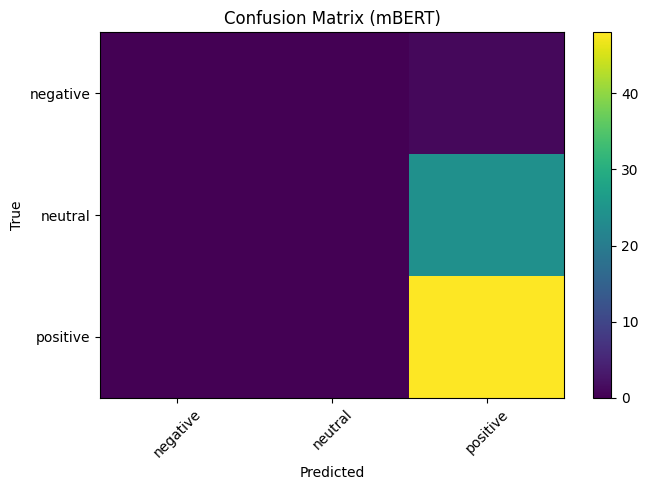


=== TABEL HASIL PREDIKSI (20 BARIS PERTAMA) ===


,text,true_label,true_label_name,predicted_label,pred_label_name,sesuai
0,kripik kulit salmon marketplace menurut saya k...,neutral,neutral,positive,positive,False
1,semua produk media sosial kripik nya sangat re...,positive,positive,positive,positive,True
2,rambak kulit cumi teman atau kerabat enak pol ...,positive,positive,positive,positive,True
3,kripik salmon kantin sekolah angat lezat penge...,positive,positive,positive,positive,True
4,rambak kulit cumi media sosial produknya cukup...,neutral,neutral,positive,positive,False
5,pisang ambon teman atau kerabat sangat enak ba...,positive,positive,positive,positive,True
6,kripik kulit salmon teman atau kerabat ini sal...,positive,positive,positive,positive,True
7,pisang ambon teman atau kerabat enak bangetttt...,positive,positive,positive,positive,True
8,semua produk teman atau kerabat rasanya mantap...,positive,positive,positive,positive,True
9,kripik salmon kantin sekolah menurut saya adai...,neutral,neutral,positive,positive,False



=== CONTOH PREDIKSI SALAH (sesuai = False) - TOP 20 ===


,text,true_label,true_label_name,predicted_label,pred_label_name,sesuai
0,kripik kulit salmon marketplace menurut saya k...,neutral,neutral,positive,positive,False
4,rambak kulit cumi media sosial produknya cukup...,neutral,neutral,positive,positive,False
9,kripik salmon kantin sekolah menurut saya adai...,neutral,neutral,positive,positive,False
15,semua produk teman atau kerabat kak keripik ku...,neutral,neutral,positive,positive,False
16,kripik kulit salmon marketplace shopee tiktok ...,neutral,neutral,positive,positive,False
20,semua produk kantin sekolah gatau pas beli itu...,neutral,neutral,positive,positive,False
27,kripik kulit salmon kantin sekolah rasanya bik...,neutral,neutral,positive,positive,False
28,pisang ambon teman atau kerabat sudah lumayan ...,neutral,neutral,positive,positive,False
30,rambak kulit cumi marketplace shopee tiktok sa...,neutral,neutral,positive,positive,False
31,pisang ambon kantin sekolah rekomendasi banget...,neutral,neutral,positive,positive,False



=== CONTOH PREDIKSI BENAR (sesuai = True) - TOP 20 ===


...


=== HASIL JOIN (prediksi sentimen + rating) - sample ===


,text,true_label,predicted_label,overall_rating
0,kripik kulit salmon marketplace menurut saya k...,neutral,positive,NaN
1,semua produk media sosial kripik nya sangat re...,positive,positive,NaN
2,rambak kulit cumi teman atau kerabat enak pol ...,positive,positive,NaN
3,kripik salmon kantin sekolah angat lezat penge...,positive,positive,NaN
4,rambak kulit cumi media sosial produknya cukup...,neutral,positive,NaN
5,pisang ambon teman atau kerabat sangat enak ba...,positive,positive,NaN
6,kripik kulit salmon teman atau kerabat ini sal...,positive,positive,NaN
7,pisang ambon teman atau kerabat enak bangetttt...,positive,positive,NaN
8,semua produk teman atau kerabat rasanya mantap...,positive,positive,NaN
9,kripik salmon kantin sekolah menurut saya adai...,neutral,positive,NaN



=== CROSSTAB: predicted_label vs rating_cat ===


rating_cat,unknown
predicted_label,
positive,73



Crosstab valid kosong, Chi-Square tidak dijalankan.


In [ ]:
# =====================================================
# MBERT SENTIMENT ANALYSIS - FULL PIPELINE (sesuai mbert final.ipynb)
# Catatan: Kode di bawah TIDAK mengubah model/arsitektur/training,
# hanya menambahkan tabel hasil prediksi (teks + label asli + label prediksi + status sesuai/tidak).
# =====================================================

import os

# =========================
# 0) CONFIG PATH FILE EXCEL (Sentimen.xlsx)
# =========================
POSSIBLE_PATHS = [
    "/content/Sentimen.xlsx",
    "/mnt/data/Sentimen.xlsx",
    "Sentimen.xlsx",
    "/content/sentimen.xlsx",
    "/mnt/data/sentimen.xlsx",
    "sentimen.xlsx",
]
SENTIMENT_XLSX_PATH = next((p for p in POSSIBLE_PATHS if os.path.exists(p)), None)
if SENTIMENT_XLSX_PATH is None:
    raise FileNotFoundError(
        "Sentimen.xlsx tidak ditemukan. Pastikan file sudah di-upload. "
        "Coba simpan di /content/ atau /mnt/data/."
    )

print("File Sentimen dipakai:", SENTIMENT_XLSX_PATH)

# Helper display (biar aman di notebook/non-notebook)
try:
    from IPython.display import display
except Exception:
    def display(x):
        print(x)


# =====================================================
# SCRIPT 1: DATA PREPROCESSING (SENTIMEN ONLY)
# =====================================================

import pandas as pd
import numpy as np
import re
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

def preprocess_sentiment_data():
    """Preprocessing data sentimen"""
    print("\n=== PREPROCESSING SENTIMENT DATA ===")
    try:
        df_sentiment = pd.read_excel(SENTIMENT_XLSX_PATH)
        print(f"Loaded sentiment data: {df_sentiment.shape}")

        df_processed = df_sentiment.copy()

        # Identify rating columns (1-6 scale) and text columns
        rating_columns = []
        text_columns = []

        for col in df_processed.columns:
            if df_processed[col].dtype in ['int64', 'float64']:
                if df_processed[col].min() >= 1 and df_processed[col].max() <= 6:
                    rating_columns.append(col)
            elif df_processed[col].dtype == 'object':
                excluded_cols = ['Timestamp', 'Nama', 'Usia', 'Domisili', 'Jenis Kelamin']
                if not any(excl.lower() in col.lower() for excl in excluded_cols):
                    text_columns.append(col)

        print(f"Rating columns found: {len(rating_columns)}")
        print(f"Text columns found: {len(text_columns)}")

        # Calculate overall rating
        if rating_columns:
            df_processed['overall_rating'] = df_processed[rating_columns].mean(axis=1)
            df_processed['rating_std'] = df_processed[rating_columns].std(axis=1).fillna(0)
        else:
            df_processed['overall_rating'] = 3.5
            df_processed['rating_std'] = 0

        # Sentiment categorization
        def categorize_sentiment(rating):
            if rating >= 4.5:
                return 'positive'
            elif rating >= 3.5:
                return 'neutral'
            else:
                return 'negative'

        df_processed['sentiment_label'] = df_processed['overall_rating'].apply(categorize_sentiment)

        # Combine text columns
        if text_columns:
            combined_texts = []
            for idx in range(len(df_processed)):
                row_texts = []
                for col in text_columns:
                    text_val = df_processed[col].iloc[idx]
                    if pd.notna(text_val) and str(text_val).strip():
                        row_texts.append(str(text_val))
                combined_texts.append(' '.join(row_texts) if row_texts else 'produk bagus')
            df_processed['combined_text'] = combined_texts
        else:
            df_processed['combined_text'] = 'produk bagus'

        # Clean text
        def clean_text(text):
            if pd.isna(text) or text == '':
                return 'produk bagus'
            text = str(text).lower()
            text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
            text = re.sub(r'\s+', ' ', text).strip()
            return text if len(text) >= 5 else 'produk bagus'

        df_processed['processed_text'] = df_processed['combined_text'].apply(clean_text)

        # Encode sentiment label
        label_encoder = LabelEncoder()
        df_processed['sentiment_encoded'] = label_encoder.fit_transform(df_processed['sentiment_label'])

        print(f"Sentiment distribution: {df_processed['sentiment_label'].value_counts().to_dict()}")

        # Save processed outputs
        df_processed.to_csv('sentiment_processed.csv', index=False)

        # Save data for BERT
        df_processed[['processed_text']].rename(columns={'processed_text': 'text'}).to_csv('bert_texts.csv', index=False)
        df_processed[['sentiment_encoded']].rename(columns={'sentiment_encoded': 'label'}).to_csv('bert_labels.csv', index=False)

        # Save label encoder
        import pickle
        with open('label_encoder.pkl', 'wb') as f:
            pickle.dump(label_encoder, f)

        print(f"Processed sentiment data saved: {df_processed.shape}")
        return df_processed

    except FileNotFoundError:
        print("File Sentimen.xlsx tidak ditemukan!")
        raise
    except Exception as e:
        print(f"Error in sentiment preprocessing: {e}")
        raise


# =====================================================
# RUN PREPROCESSING
# =====================================================

print("="*60)
print("STEP 1: DATA PREPROCESSING (SENTIMEN SAJA)")
print("="*60)

sentiment_data = preprocess_sentiment_data()

print("\nPREPROCESSING COMPLETED!")


# =====================================================
# SMART DATA RE-LABELING FOR BETTER SENTIMENT ANALYSIS
# =====================================================

import pandas as pd
import numpy as np
import re
from collections import Counter
import pickle

def smart_sentiment_labeling(texts, manual_review=True):
    """
    Smart rule-based labeling untuk data Pawonkoe
    dengan review manual untuk akurasi tinggi
    """

    # Expanded Indonesian sentiment keywords for food/product reviews
    positive_patterns = {
        'taste_positive': ['enak', 'lezat', 'mantap', 'gurih', 'renyah', 'nikmat', 'maknyus', 'jos', 'sedap'],
        'quality_positive': ['bagus', 'berkualitas', 'terbaik', 'sempurna', 'istimewa', 'hebat', 'keren', 'top'],
        'satisfaction': ['puas', 'suka', 'senang', 'recommended', 'recommend', 'sukai', 'cocok'],
        'freshness': ['fresh', 'segar', 'baru', 'krispy', 'krispi'],
        'approval': ['iya beli lagi', 'akan beli', 'good', 'oke banget', 'worth it'],
    }

    negative_patterns = {
        'taste_negative': ['hambar', 'tidak enak', 'kurang enak', 'aneh rasanya', 'basi', 'tengik'],
        'quality_negative': ['buruk', 'jelek', 'payah', 'gagal', 'rusak', 'cacat', 'tidak bagus'],
        'dissatisfaction': ['kecewa', 'tidak puas', 'mengecewakan', 'tidak suka', 'tidak cocok'],
        'problems': ['terlalu mahal', 'kemahalan', 'susah didapat', 'kehabisan', 'sold out'],
        'complaints': ['complain', 'protes', 'tidak akan beli', 'tidak recommend'],
    }

    neutral_patterns = {
        'moderate': ['lumayan', 'biasa aja', 'biasa saja', 'standar', 'normal', 'rata-rata'],
        'conditional': ['tergantung', 'kadang', 'sometimes', 'cukup', 'ok', 'oke'],
        'mixed': ['ada plus minus', 'setengah setengah', 'fifty fifty'],
    }

    def calculate_sentiment_score(text):
        """Hitung sentiment score berdasarkan pattern matching"""
        text_clean = text.lower().strip()

        # Remove punctuation for better matching
        text_words = re.findall(r'\b\w+\b', text_clean)
        text_joined = ' '.join(text_words)

        pos_score = 0
        neg_score = 0
        neu_score = 0

        # Count positive patterns
        for category, patterns in positive_patterns.items():
            for pattern in patterns:
                if pattern in text_joined:
                    pos_score += 2 if category in ['satisfaction', 'quality_positive'] else 1

        # Count negative patterns
        for category, patterns in negative_patterns.items():
            for pattern in patterns:
                if pattern in text_joined:
                    neg_score += 2 if category in ['dissatisfaction', 'quality_negative'] else 1

        # Count neutral patterns
        for category, patterns in neutral_patterns.items():
            for pattern in patterns:
                if pattern in text_joined:
                    neu_score += 1

        # Handle negations (very important!)
        negation_words = ['tidak', 'bukan', 'gak', 'ga', 'enggak', 'nggak']
        for negation in negation_words:
            if negation in text_words:
                # Find what comes after negation
                try:
                    neg_idx = text_words.index(negation)
                    if neg_idx < len(text_words) - 1:
                        next_word = text_words[neg_idx + 1]
                        # If negating positive word, increase negative score
                        for patterns in positive_patterns.values():
                            if next_word in patterns:
                                neg_score += 2
                                pos_score = max(0, pos_score - 1)
                        # If negating negative word, increase positive score
                        for patterns in negative_patterns.values():
                            if next_word in patterns:
                                pos_score += 2
                                neg_score = max(0, neg_score - 1)
                except ValueError:
                    pass

        return pos_score, neg_score, neu_score

    results = []

    for text in texts:
        if pd.isna(text) or str(text).strip() == '':
            text = 'produk bagus'

        pos_score, neg_score, neu_score = calculate_sentiment_score(str(text))

        # Decision logic
        if pos_score > neg_score and pos_score > neu_score and pos_score > 0:
            predicted_label = 'positive'
            confidence = pos_score / (pos_score + neg_score + neu_score + 1)
        elif neg_score > pos_score and neg_score > neu_score and neg_score > 0:
            predicted_label = 'negative'
            confidence = neg_score / (pos_score + neg_score + neu_score + 1)
        else:
            predicted_label = 'neutral'
            confidence = 0.5

        results.append({
            'text': text,
            'predicted_label': predicted_label,
            'pos_score': pos_score,
            'neg_score': neg_score,
            'neu_score': neu_score,
            'confidence': confidence
        })

    results_df = pd.DataFrame(results)

    # Manual review simulation (optional)
    if manual_review:
        print("\n=== MANUAL REVIEW SUGGESTION ===")
        low_conf = results_df[results_df['confidence'] < 0.6]
        high_conf = results_df[results_df['confidence'] > 0.7]

        print(f"Low confidence samples: {len(low_conf)}")
        print(f"High confidence samples: {len(high_conf)}")

    # Save corrected outputs (as final labels)
    final_labels = results_df['predicted_label'].tolist()

    texts_df = pd.DataFrame({'text': texts})
    labels_df = pd.DataFrame({'label': final_labels})

    texts_df.to_csv('corrected_bert_texts.csv', index=False)
    labels_df.to_csv('corrected_bert_labels.csv', index=False)
    results_df.to_csv('relabeling_analysis.csv', index=False)

    # Label encoding
    from sklearn.preprocessing import LabelEncoder
    label_encoder = LabelEncoder()
    encoded_labels = label_encoder.fit_transform(final_labels)

    with open('corrected_label_encoder.pkl', 'wb') as f:
        pickle.dump(label_encoder, f)

    print("\nSaved files:")
    print("- corrected_bert_texts.csv")
    print("- corrected_bert_labels.csv")
    print("- relabeling_analysis.csv")
    print("- corrected_label_encoder.pkl")

    return results_df, label_encoder


print("\n" + "="*60)
print("STEP 2: SMART RE-LABELING (RULE-BASED)")
print("="*60)

# Load previous processed texts
texts_df = pd.read_csv('bert_texts.csv')
texts = texts_df['text'].astype(str).tolist()

relabeling_results, corrected_le = smart_sentiment_labeling(texts, manual_review=True)

print("\nRE-LABELING COMPLETED!")


# =====================================================
# SCRIPT 2: TRAINING & EVALUATION mBERT
# =====================================================

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import pickle
import warnings
warnings.filterwarnings('ignore')

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load corrected datasets
texts_df = pd.read_csv("corrected_bert_texts.csv")
labels_df = pd.read_csv("corrected_bert_labels.csv")

texts = texts_df["text"].astype(str).tolist()
final_labels = labels_df["label"].astype(str).tolist()

# Load label encoder
with open("corrected_label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

labels = label_encoder.transform(final_labels)

print("Total samples:", len(texts))
print("Classes:", list(label_encoder.classes_))

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    texts, labels,
    test_size=0.2,
    random_state=42,
    stratify=labels if len(np.unique(labels)) > 1 else None
)

# Dataset
class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        encoding = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt',
            add_special_tokens=True
        )
        item = {key: val.squeeze(0) for key, val in encoding.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        item['text'] = text
        return item

# Model
class MBERTClassifier(nn.Module):
    def __init__(self, num_classes=3, dropout_rate=0.3, freeze_layers=6):
        super().__init__()
        self.bert = AutoModel.from_pretrained('bert-base-multilingual-cased')

        # Freeze first N layers
        for param in self.bert.embeddings.parameters():
            param.requires_grad = False

        if hasattr(self.bert, "encoder"):
            for layer in self.bert.encoder.layer[:freeze_layers]:
                for param in layer.parameters():
                    param.requires_grad = False

        hidden_size = self.bert.config.hidden_size
        self.dropout = nn.Dropout(dropout_rate)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_size // 2, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.pooler_output
        logits = self.classifier(self.dropout(pooled_output))
        return logits

# Hyperparameters (sesuai notebook)
MAX_LENGTH = 128
BATCH_SIZE = 8
EPOCHS = 5
LEARNING_RATE = 2e-5

tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')

train_dataset = SentimentDataset(X_train, y_train, tokenizer, max_length=MAX_LENGTH)
test_dataset  = SentimentDataset(X_test, y_test, tokenizer, max_length=MAX_LENGTH)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

num_classes = len(np.unique(labels)) if len(np.unique(labels)) > 1 else 3
model = MBERTClassifier(num_classes=num_classes, dropout_rate=0.3, freeze_layers=6).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

best_acc = 0.0
best_state = None

print("\n" + "="*60)
print("STEP 3: TRAINING mBERT")
print("="*60)

for epoch in range(EPOCHS):
    model.train()
    epoch_losses = []
    all_preds = []
    all_true = []

    for batch in train_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels_batch = batch['labels'].to(device)

        optimizer.zero_grad()
        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels_batch)
        loss.backward()
        optimizer.step()

        epoch_losses.append(loss.item())
        preds = torch.argmax(logits, dim=1).detach().cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(labels_batch.detach().cpu().numpy())

    train_acc = accuracy_score(all_true, all_preds)
    train_f1  = f1_score(all_true, all_preds, average='weighted')

    # Validation
    model.eval()
    val_preds = []
    val_true = []
    val_probs = []
    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels_batch = batch['labels'].to(device)

            logits = model(input_ids, attention_mask)
            probs = torch.softmax(logits, dim=1).detach().cpu().numpy()
            preds = np.argmax(probs, axis=1)

            val_probs.extend(probs)
            val_preds.extend(preds)
            val_true.extend(labels_batch.detach().cpu().numpy())

    val_acc = accuracy_score(val_true, val_preds)
    val_f1  = f1_score(val_true, val_preds, average='weighted')

    print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {np.mean(epoch_losses):.4f} | "
          f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")

    if val_acc > best_acc:
        best_acc = val_acc
        best_state = model.state_dict()

# Save best model
torch.save(best_state, 'best_bert_model.pth')
print("\nBest validation accuracy:", best_acc)
print("Saved: best_bert_model.pth")

# Load best state for final test output
model.load_state_dict(best_state)
model.eval()

# Collect final predictions + probabilities + keep text
all_texts = []
all_true = []
all_preds = []
all_probs = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels_batch = batch['labels'].to(device)

        logits = model(input_ids, attention_mask)
        probs = torch.softmax(logits, dim=1).detach().cpu().numpy()
        preds = np.argmax(probs, axis=1)

        all_probs.extend(probs)
        all_preds.extend(preds)
        all_true.extend(labels_batch.detach().cpu().numpy())
        all_texts.extend(batch['text'])

# Convert numeric labels back to original string labels (from encoder)
true_labels_str = label_encoder.inverse_transform(np.array(all_true))
pred_labels_str = label_encoder.inverse_transform(np.array(all_preds))

# Create sentiment features output (sesuai notebook)
sentiment_features = []
for i, (text, true_label) in enumerate(zip(all_texts, true_labels_str)):
    probs = all_probs[i]
    pred = pred_labels_str[i]

    if len(probs) == 3:
        features = {
            'text': text,
            'true_label': true_label,
            'predicted_label': pred,
            'negative_prob': probs[0],
            'neutral_prob': probs[1],
            'positive_prob': probs[2],
            'confidence': np.max(probs),
            'sentiment_score': probs[2] - probs[0] if len(probs) > 2 else probs[-1] - probs[0]
        }
    else:
        features = {
            'text': text,
            'true_label': true_label,
            'predicted_label': pred,
            'negative_prob': probs[0] if len(probs) > 0 else 0,
            'neutral_prob': probs[1] if len(probs) > 1 else 0,
            'positive_prob': probs[2] if len(probs) > 2 else probs[-1],
            'confidence': np.max(probs),
            'sentiment_score': probs[-1] - probs[0]
        }

    sentiment_features.append(features)

sentiment_features_df = pd.DataFrame(sentiment_features)

# Save results (sesuai notebook)
tokenizer.save_pretrained('bert_tokenizer')
sentiment_features_df.to_csv('sentiment_features_for_xgboost.csv', index=False)

with open('bert_results.pkl', 'wb') as f:
    pickle.dump({
        'test_accuracy': best_acc,
        'model_path': 'best_bert_model.pth',
        'tokenizer_path': 'bert_tokenizer'
    }, f)

print(f"\nFiles saved:")
print(f"- best_bert_model.pth")
print(f"- bert_tokenizer/")
print(f"- sentiment_features_for_xgboost.csv")
print(f"- bert_results.pkl")


# =====================================================
# TAMBAHAN B: Confusion Matrix + Classification Report (Evaluasi)
# =====================================================

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load hasil prediksi (output dari step training di atas)
bert_out = pd.read_csv("sentiment_features_for_xgboost.csv")

y_true = bert_out["true_label"].astype(str)
y_pred = bert_out["predicted_label"].astype(str)

labels = sorted(list(set(y_true.unique()) | set(y_pred.unique())))

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred, labels=labels))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels])

print("\n=== CONFUSION MATRIX (TABEL) ===")
display(cm_df)

# Plot heatmap confusion matrix
plt.figure(figsize=(7, 5))
plt.imshow(cm, aspect="auto")
plt.xticks(range(len(labels)), labels, rotation=45)
plt.yticks(range(len(labels)), labels)
plt.colorbar()
plt.title("Confusion Matrix (mBERT)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

# ============================================================
# ✅ TAMBAHAN (REVISI DOSEN):
# TABEL HASIL PREDIKSI PER KALIMAT (teks + label asli + label prediksi)
# ============================================================
# Keterangan:
# - kolom 'sesuai' = True jika predicted_label == true_label
# - tampilkan contoh data salah & benar supaya ada bukti "kalimat sudah sesuai / belum"
#
# File bert_out sudah punya kolom 'text' (kalimat), 'true_label', 'predicted_label'
# karena dibuat di tahap training (lihat sentiment_features_for_xgboost.csv).

tabel_hasil_pred = bert_out[['text','true_label','predicted_label']].copy()
tabel_hasil_pred['sesuai'] = (tabel_hasil_pred['true_label'].astype(str) == tabel_hasil_pred['predicted_label'].astype(str))

# (opsional) mapping label angka -> nama label, jika label berupa 0/1/2
label_map = {0:'negative', 1:'neutral', 2:'positive', '0':'negative', '1':'neutral', '2':'positive'}
tabel_hasil_pred['true_label_name'] = tabel_hasil_pred['true_label'].map(label_map).fillna(tabel_hasil_pred['true_label'].astype(str))
tabel_hasil_pred['pred_label_name'] = tabel_hasil_pred['predicted_label'].map(label_map).fillna(tabel_hasil_pred['predicted_label'].astype(str))

# Rapikan urutan kolom
tabel_hasil_pred = tabel_hasil_pred[['text','true_label','true_label_name','predicted_label','pred_label_name','sesuai']]

print("\n=== TABEL HASIL PREDIKSI (20 BARIS PERTAMA) ===")
display(tabel_hasil_pred.head(20))

print("\n=== CONTOH PREDIKSI SALAH (sesuai = False) - TOP 20 ===")
display(tabel_hasil_pred[tabel_hasil_pred['sesuai'] == False].head(20))

print("\n=== CONTOH PREDIKSI BENAR (sesuai = True) - TOP 20 ===")
display(tabel_hasil_pred[tabel_hasil_pred['sesuai'] == True].head(20))

# (opsional) simpan ke Excel untuk lampiran laporan
tabel_hasil_pred.to_excel("tabel_hasil_prediksi_mbert.xlsx", index=False)
print("\nFile tabel disimpan: tabel_hasil_prediksi_mbert.xlsx")


# =====================================================
# TAMBAHAN C: Load data rating kepuasan + rapihkan kolom
# =====================================================

import pandas as pd
import numpy as np

df = pd.read_excel(SENTIMENT_XLSX_PATH)
df.columns = df.columns.astype(str).str.strip()

# Ambil kolom rating skala 1-6 (sesuai notebook)
rating_cols = []
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        if df[col].min() >= 1 and df[col].max() <= 6:
            rating_cols.append(col)

if rating_cols:
    df["overall_rating"] = df[rating_cols].mean(axis=1)
else:
    df["overall_rating"] = 3.5

print("\n=== INFO DATA RATING ===")
print("Rating cols:", rating_cols)
print("Shape:", df.shape)
display(df.head(3))


# =====================================================
# TAMBAHAN D: Sinkronisasi rating ↔ prediksi sentimen + Crosstab
# =====================================================

# bert_out berisi teks test set saja, jadi sinkronisasi sederhana via text join
# (kalau ada teks yang sama persis di df, bisa match)
df_text_candidates = [c for c in df.columns if df[c].dtype == 'object']
if len(df_text_candidates) > 0:
    # gabungkan semua kolom teks jadi satu (mirip preprocessing)
    def _combine_text_row(row):
        parts = []
        for c in df_text_candidates:
            v = row.get(c, "")
            if pd.notna(v) and str(v).strip():
                parts.append(str(v))
        return " ".join(parts) if parts else "produk bagus"

    df["combined_text_raw"] = df.apply(_combine_text_row, axis=1).astype(str)
else:
    df["combined_text_raw"] = "produk bagus"

# Clean ringan supaya lebih match ke 'text' yang dipakai training
import re
def _clean_match(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text if len(text) >= 5 else "produk bagus"

df["combined_text_clean"] = df["combined_text_raw"].apply(_clean_match)

# Join prediksi
merge_df = bert_out.copy()
merge_df["text_clean"] = merge_df["text"].apply(_clean_match)

df_merge = merge_df.merge(
    df[["combined_text_clean", "overall_rating"]],
    left_on="text_clean",
    right_on="combined_text_clean",
    how="left"
)

print("\n=== HASIL JOIN (prediksi sentimen + rating) - sample ===")
display(df_merge[["text","true_label","predicted_label","overall_rating"]].head(10))

# Crosstab sederhana: pred_label vs kategori rating
def rating_category(r):
    if pd.isna(r):
        return "unknown"
    if r >= 4.5:
        return "high"
    elif r >= 3.5:
        return "mid"
    else:
        return "low"

df_merge["rating_cat"] = df_merge["overall_rating"].apply(rating_category)

ct = pd.crosstab(df_merge["predicted_label"], df_merge["rating_cat"])
print("\n=== CROSSTAB: predicted_label vs rating_cat ===")
display(ct)


# =====================================================
# TAMBAHAN E: Uji Chi-Square + Cramer's V
# =====================================================

from scipy.stats import chi2_contingency
import numpy as np

# hanya pakai yang rating-nya ada
ct_valid = ct.copy()
if "unknown" in ct_valid.columns:
    ct_valid = ct_valid.drop(columns=["unknown"])

if ct_valid.size > 0:
    chi2, p, dof, expected = chi2_contingency(ct_valid.values)
    n = ct_valid.values.sum()
    r, k = ct_valid.shape
    cramers_v = np.sqrt((chi2 / n) / (min(k-1, r-1) if min(k-1, r-1) > 0 else 1))

    print("\n=== CHI-SQUARE TEST ===")
    print("Chi2:", chi2)
    print("p-value:", p)
    print("dof:", dof)
    print("Cramer's V:", cramers_v)
else:
    print("\nCrosstab valid kosong, Chi-Square tidak dijalankan.")


In [ ]:
import pandas as pd

df_relabel = pd.read_csv("relabeling_analysis.csv")

print("Shape:", df_relabel.shape)
display(df_relabel.head())


Shape: (365, 6)


,text,predicted_label,pos_score,neg_score,neu_score,confidence
0,kripik salmon teman atau kerabat mantap enak i...,positive,2,0,0,0.6667
1,kripik kulit salmon teman atau kerabat enak gu...,positive,3,0,0,0.7500
2,rambak kulit cumi teman atau kerabat produk ra...,positive,3,0,2,0.5000
3,rambak kulit cumi marketplace shopee tiktok ra...,positive,2,0,1,0.5000
4,pisang ambon teman atau kerabat pertama kali b...,positive,1,0,0,0.5000


In [ ]:
print(df_relabel.columns.tolist())


['text', 'predicted_label', 'pos_score', 'neg_score', 'neu_score', 'confidence']


In [ ]:
print(df_relabel["predicted_label"].value_counts())



predicted_label
positive    239
neutral     123
negative      3
Name: count, dtype: int64


In [ ]:
df_low_conf = df_relabel[df_relabel["confidence"] < 0.6]
display(df_low_conf.head(10))


,text,predicted_label,pos_score,neg_score,neu_score,confidence
2,rambak kulit cumi teman atau kerabat produk ra...,positive,3,0,2,0.5000
3,rambak kulit cumi marketplace shopee tiktok ra...,positive,2,0,1,0.5000
4,pisang ambon teman atau kerabat pertama kali b...,positive,1,0,0,0.5000
5,pisang ambon marketplace shopee tiktok enak ma...,neutral,1,0,1,0.5000
8,rambak kulit cumi media sosial produknya cukup...,neutral,1,0,1,0.5000
10,rambak kulit cumi teman atau kerabat tidak ber...,neutral,0,0,0,0.5000
11,pisang ambon marketplace shopee tiktok menurut...,positive,3,0,2,0.5000
13,semua produk media sosial pawonkoe kripiknya e...,positive,2,0,1,0.5000
15,pisang ambon media sosial lagi galau no komen ...,positive,1,0,0,0.5000
18,semua produk teman atau kerabat crispy n crunc...,neutral,0,0,0,0.5000


In [ ]:
df_negative = df_relabel[df_relabel["predicted_label"] == "negative"]

print("Jumlah data negative:", len(df_negative))
display(df_negative)


Jumlah data negative: 3


,text,predicted_label,pos_score,neg_score,neu_score,confidence
105,pisang ambon media sosial dari apa yang sudah ...,negative,0,3,1,0.6000
160,kripik kulit salmon kantin sekolah aku beli te...,negative,0,2,0,0.6667
251,pisang ambon kantin sekolah kurang banget di a...,negative,1,2,0,0.5000


In [ ]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)  # biar teks gak kepotong
display(df_relabel[["text","predicted_label","confidence"]])


,text,predicted_label,confidence
0,kripik salmon teman atau kerabat mantap enak iya iya coba bikin produk yang pedes2 dan bervarasi,positive,0.6667
1,kripik kulit salmon teman atau kerabat enak gurih dan krispi iya tidak semoga lebih banyak cabang offline store,positive,0.7500
2,rambak kulit cumi teman atau kerabat produk rambak kulit cumi ya lumayanlah gurih dan bumbunya agak berasa cocok sebagai camilan yang praktis iya iya tambahkan produk inovasi yamg lebih banyak lagi dari produk yang dijual sekarang,positive,0.5000
3,rambak kulit cumi marketplace shopee tiktok rasanya enak dan harga terjangkau iya iya mungkin bisa diperbarui desain kemasannya agar lebih menarik,positive,0.5000
4,pisang ambon teman atau kerabat pertama kali beli pisang ambon nya disini itu rasanya enak bgt iya iya mungkin pengiklanannya lebih di sebar luaskan agar produk seenak ini bisa dikenal banyak orang,positive,0.5000
5,pisang ambon marketplace shopee tiktok enak manis iya iya mungkin adanya inovasi penambahan berbagai macam rasa,neutral,0.5000
6,semua produk teman atau kerabat renyah gurih dan harga terjangkau mantap deh pokonya iya iya tetap di jaga kwalitasnya,positive,0.6000
7,semua produk media sosial cocok enak semua lain daripada yang lain iya iya harus sering di tawarkan lewat media apa saja,positive,0.6000
8,rambak kulit cumi media sosial produknya cukup enak untuk dibuat cemilan sambil nonton iya iya lebih banyak porsi dengan harga yang tetap,neutral,0.5000
9,kripik kulit salmon media sosial enak renyah gak terlalu berminyak iya iya kemasannya bisa dimodifikasi agar lebih menarik untuk produknya sendiri sudah enak,positive,0.6667


In [ ]:
import pandas as pd

pd.set_option("display.max_colwidth", None)  # supaya teks tidak terpotong

# Ambil masing-masing 3 data per kelas
df_pos = df_relabel[df_relabel["predicted_label"] == "positive"].head(3)
df_neu = df_relabel[df_relabel["predicted_label"] == "neutral"].head(3)
df_neg = df_relabel[df_relabel["predicted_label"] == "negative"].head(3)

# Gabungkan
df_sample = pd.concat([df_pos, df_neu, df_neg])

print("=== 3 DATA PER KELAS ===")
display(df_sample)


=== 3 DATA PER KELAS ===


,text,predicted_label,pos_score,neg_score,neu_score,confidence
0,kripik salmon teman atau kerabat mantap enak iya iya coba bikin produk yang pedes2 dan bervarasi,positive,2,0,0,0.6667
1,kripik kulit salmon teman atau kerabat enak gurih dan krispi iya tidak semoga lebih banyak cabang offline store,positive,3,0,0,0.7500
2,rambak kulit cumi teman atau kerabat produk rambak kulit cumi ya lumayanlah gurih dan bumbunya agak berasa cocok sebagai camilan yang praktis iya iya tambahkan produk inovasi yamg lebih banyak lagi dari produk yang dijual sekarang,positive,3,0,2,0.5000
5,pisang ambon marketplace shopee tiktok enak manis iya iya mungkin adanya inovasi penambahan berbagai macam rasa,neutral,1,0,1,0.5000
8,rambak kulit cumi media sosial produknya cukup enak untuk dibuat cemilan sambil nonton iya iya lebih banyak porsi dengan harga yang tetap,neutral,1,0,1,0.5000
10,rambak kulit cumi teman atau kerabat tidak berminyak iya iya kemasan diperbanyak isinya,neutral,0,0,0,0.5000
105,pisang ambon media sosial dari apa yang sudah saya beli kripik pisangngnya terasa tidak enak di tenggorokan jadi membekas setelah berhenti makan iya tidak tingkatkan lagi dari segi menggoreng atau memasaknya dan perhatikan dari segi minyaknya,negative,0,3,1,0.6000
160,kripik kulit salmon kantin sekolah aku beli terakhir kripiknya ga gurih mungkin udh terlalu lama padahal sebelumnya aman aman aja dan gurih iya tidak tambahkan rasa cabai rawit,negative,0,2,0,0.6667
251,pisang ambon kantin sekolah kurang banget di aku pisangnya kurang gurih terus terlalu manis banget jadi ga enak tidak tidak buat kemasan travel edition,negative,1,2,0,0.5000


In [ ]:
df_sample = pd.concat([df_pos, df_neu, df_neg]).reset_index(drop=True)
display(df_sample)


,text,predicted_label,pos_score,neg_score,neu_score,confidence
0,kripik salmon teman atau kerabat mantap enak iya iya coba bikin produk yang pedes2 dan bervarasi,positive,2,0,0,0.6667
1,kripik kulit salmon teman atau kerabat enak gurih dan krispi iya tidak semoga lebih banyak cabang offline store,positive,3,0,0,0.7500
2,rambak kulit cumi teman atau kerabat produk rambak kulit cumi ya lumayanlah gurih dan bumbunya agak berasa cocok sebagai camilan yang praktis iya iya tambahkan produk inovasi yamg lebih banyak lagi dari produk yang dijual sekarang,positive,3,0,2,0.5000
3,pisang ambon marketplace shopee tiktok enak manis iya iya mungkin adanya inovasi penambahan berbagai macam rasa,neutral,1,0,1,0.5000
4,rambak kulit cumi media sosial produknya cukup enak untuk dibuat cemilan sambil nonton iya iya lebih banyak porsi dengan harga yang tetap,neutral,1,0,1,0.5000
5,rambak kulit cumi teman atau kerabat tidak berminyak iya iya kemasan diperbanyak isinya,neutral,0,0,0,0.5000
6,pisang ambon media sosial dari apa yang sudah saya beli kripik pisangngnya terasa tidak enak di tenggorokan jadi membekas setelah berhenti makan iya tidak tingkatkan lagi dari segi menggoreng atau memasaknya dan perhatikan dari segi minyaknya,negative,0,3,1,0.6000
7,kripik kulit salmon kantin sekolah aku beli terakhir kripiknya ga gurih mungkin udh terlalu lama padahal sebelumnya aman aman aja dan gurih iya tidak tambahkan rasa cabai rawit,negative,0,2,0,0.6667
8,pisang ambon kantin sekolah kurang banget di aku pisangnya kurang gurih terus terlalu manis banget jadi ga enak tidak tidak buat kemasan travel edition,negative,1,2,0,0.5000
